In [ ]:
"""
Created on Wednesday Feb 26 2025

@author: Fatemeh Esmaeili
"""
import pandas as pd
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

In [ ]:
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

In [ ]:
class CVAE(nn.Module):
    def __init__(self, input_dim_1, input_dim_2, demo_dim, latent_dim):
        super(CVAE, self).__init__()
        self.demo_dim = demo_dim

        # Encoder for modality 1
        self.encoder_1 = nn.Sequential(
            nn.Linear(input_dim_1 + demo_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
        self.fc_mu_1 = nn.Linear(32, latent_dim)
        self.fc_logvar_1 = nn.Linear(32, latent_dim)

        # Encoder for modality 2
        self.encoder_2 = nn.Sequential(
            nn.Linear(input_dim_2 + demo_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
        self.fc_mu_2 = nn.Linear(32, latent_dim)
        self.fc_logvar_2 = nn.Linear(32, latent_dim)

        # Decoder
        self.decoder_1 = nn.Sequential(
            nn.Linear(latent_dim + demo_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim_1)
        )

        self.decoder_2 = nn.Sequential(
            nn.Linear(latent_dim + demo_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim_2)
        )

    def encode(self, x1, x2, demo):
        # Encode each modality separately
        x1 = torch.cat((x1, demo), dim=1)
        x2 = torch.cat((x2, demo), dim=1)
        hidden_1 = self.encoder_1(x1)
        hidden_2 = self.encoder_2(x2)
        mu_1, logvar_1 = self.fc_mu_1(hidden_1), self.fc_logvar_1(hidden_1)
        mu_2, logvar_2 = self.fc_mu_2(hidden_2), self.fc_logvar_2(hidden_2)
        return mu_1, logvar_1, mu_2, logvar_2

    def product_of_experts(self, mu_list, logvar_list):
        """
        Compute the Product of Experts (PoE) mean and log-variance.

        Args:
            mu_list (list of tensors): Means from individual modalities.
            logvar_list (list of tensors): Log-variances from individual modalities.

        Returns:
            (mu_poe, logvar_poe): PoE mean and log-variance.
        """
        precisions = [torch.exp(-logvar) for logvar in logvar_list] # T_i = exp(-logvar)
        precision_sum = sum(precisions) # Sum of precisions
        variance_poe = 1.0 / precision_sum # Variance
        weighted_mu_sum = sum(mu * precision for mu, precision in zip(mu_list, precisions))
        mu_poe = weighted_mu_sum * variance_poe  # Weighted mean
        logvar_poe = torch.log(variance_poe) # Log-variance
        return mu_poe, logvar_poe

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, demo):
        # Decode into both modalities
        z = torch.cat((z, demo), dim=1)
        recon_1 = self.decoder_1(z)
        recon_2 = self.decoder_2(z)
        return recon_1, recon_2

    def forward(self, x1, x2, demo):
        mu_1, logvar_1, mu_2, logvar_2 = self.encode(x1, x2, demo)
        # Use Product of Experts (PoE) for the shared representation
        mu_poe, logvar_poe = self.product_of_experts([mu_1, mu_2], [logvar_1, logvar_2])
        z = self.reparameterize(mu_poe, logvar_poe)
        recon_1, recon_2 = self.decode(z, demo)
        return recon_1, recon_2, mu_poe, logvar_poe

In [ ]:
# Define the MVAE loss function
def cvae_loss(recon_1, recon_2, x1, x2, mu, logvar, beta):
    reconstruction_loss_1 = nn.MSELoss()(recon_1, x1)
    reconstruction_loss_2 = nn.MSELoss()(recon_2, x2)
    #kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    kld_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return reconstruction_loss_1 + reconstruction_loss_2 + beta * kld_loss
    # return reconstruction_loss_1 + reconstruction_loss_2 + kld_loss

In [ ]:
def loss_recon1_recon2(recon_1, recon_2, x1, x2, mu, logvar):
    reconstruction_loss_1 = nn.MSELoss()(recon_1, x1)
    reconstruction_loss_2 = nn.MSELoss()(recon_2, x2)
    return reconstruction_loss_1, reconstruction_loss_2

In [ ]:
# Load datasets
data_hc_modality1 = pd.read_csv('./Data/roi_demo_both_ADNI.csv') # HC data for modality 1
data_hc_modality2 = pd.read_csv('./Data/ADNI_HC_Schaefer100_TianS1_MRI.csv') # HC data for modality 2
data_ad_modality1 = pd.read_csv('./Data/roi_demo_AD_PET_ADNI.csv') # AD data for modality 1
data_ad_modality2 = pd.read_csv('./Data/roi_demo_AD_PETMRI_ADNI.csv') # AD data for modality 2

In [ ]:
# Prepare data for both modalities
X1_hc = data_hc_modality1.iloc[:, 5:].values
X2_hc = data_hc_modality2.iloc[:, 1:].values
X1_ad = data_ad_modality1.iloc[:, 6:].values
X2_ad = data_ad_modality2.iloc[:, 122:].values

In [ ]:
# Check for NaN or infinite values and clean
for X in [X1_hc, X2_hc, X1_ad, X2_ad]:
    print("Cleaning data: replacing NaN and Inf values.")
    if np.any(np.isnan(X)) or np.any(np.isinf(X)):
        X = np.nan_to_num(X, nan=np.nanmean(X), posinf=np.nanmax(X), neginf=np.nanmin(X))

Cleaning data: replacing NaN and Inf values.
Cleaning data: replacing NaN and Inf values.
Cleaning data: replacing NaN and Inf values.
Cleaning data: replacing NaN and Inf values.


In [ ]:
# We want to plot features 0 through 7
selected_features = [0, 1, 2, 3, 4, 5, 6, 7]  # Indices of features to plot
# selected_features = np.arange (115)

In [ ]:
def plot_compare_histograms(data1, data2, title1, title2, feature_indices):
    """
    Plots individual histograms for each dataset and an overlayed histogram for each selected feature.

    Parameters:
    - data1, data2: Numpy arrays of shape (226, 116).
    - feature_indices: List of feature indices to plot (max 8 features).
    """
    num_features = len(feature_indices)

    titles = [title1, title2]
    data_sets = [data1, data2]
    colors = ["blue", "cyan"]

    fig, axes = plt.subplots(num_features, 3, figsize=(25, num_features * 3))  # 3 columns per feature
    fig.suptitle("Histogram Comparisons with Overlay for Each Feature", fontsize=16)

    for row_idx, feature in enumerate(feature_indices):
        # Plot individual histograms
        for col_idx in range(2):
            ax = axes[row_idx, col_idx]
            # Check if data is 1D or 2D
            if data_sets[col_idx].ndim == 1:
                data_to_plot = data_sets[col_idx]
            else:
                data_to_plot = data_sets[col_idx][:, feature]

            ax.hist(data_to_plot, bins=20, alpha=0.7, color=colors[col_idx])
            ax.set_title(f"Feature {feature+1} - {titles[col_idx]}")
            ax.set_xlabel("Value")
            ax.set_ylabel("Frequency")

        # Plot overlayed histogram in the last column
        ax = axes[row_idx, 2]
        for data, color, label in zip(data_sets, colors, titles):
            if data.ndim == 1:
                data_to_plot = data
            else:
                data_to_plot = data[:, feature]
            ax.hist(data_to_plot, bins=20, alpha=0.5, color=color, label=label)
        ax.set_title(f"Feature {feature+1} - Overlay")
        ax.set_xlabel("Value")
        ax.set_ylabel("Frequency")
        ax.legend()

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

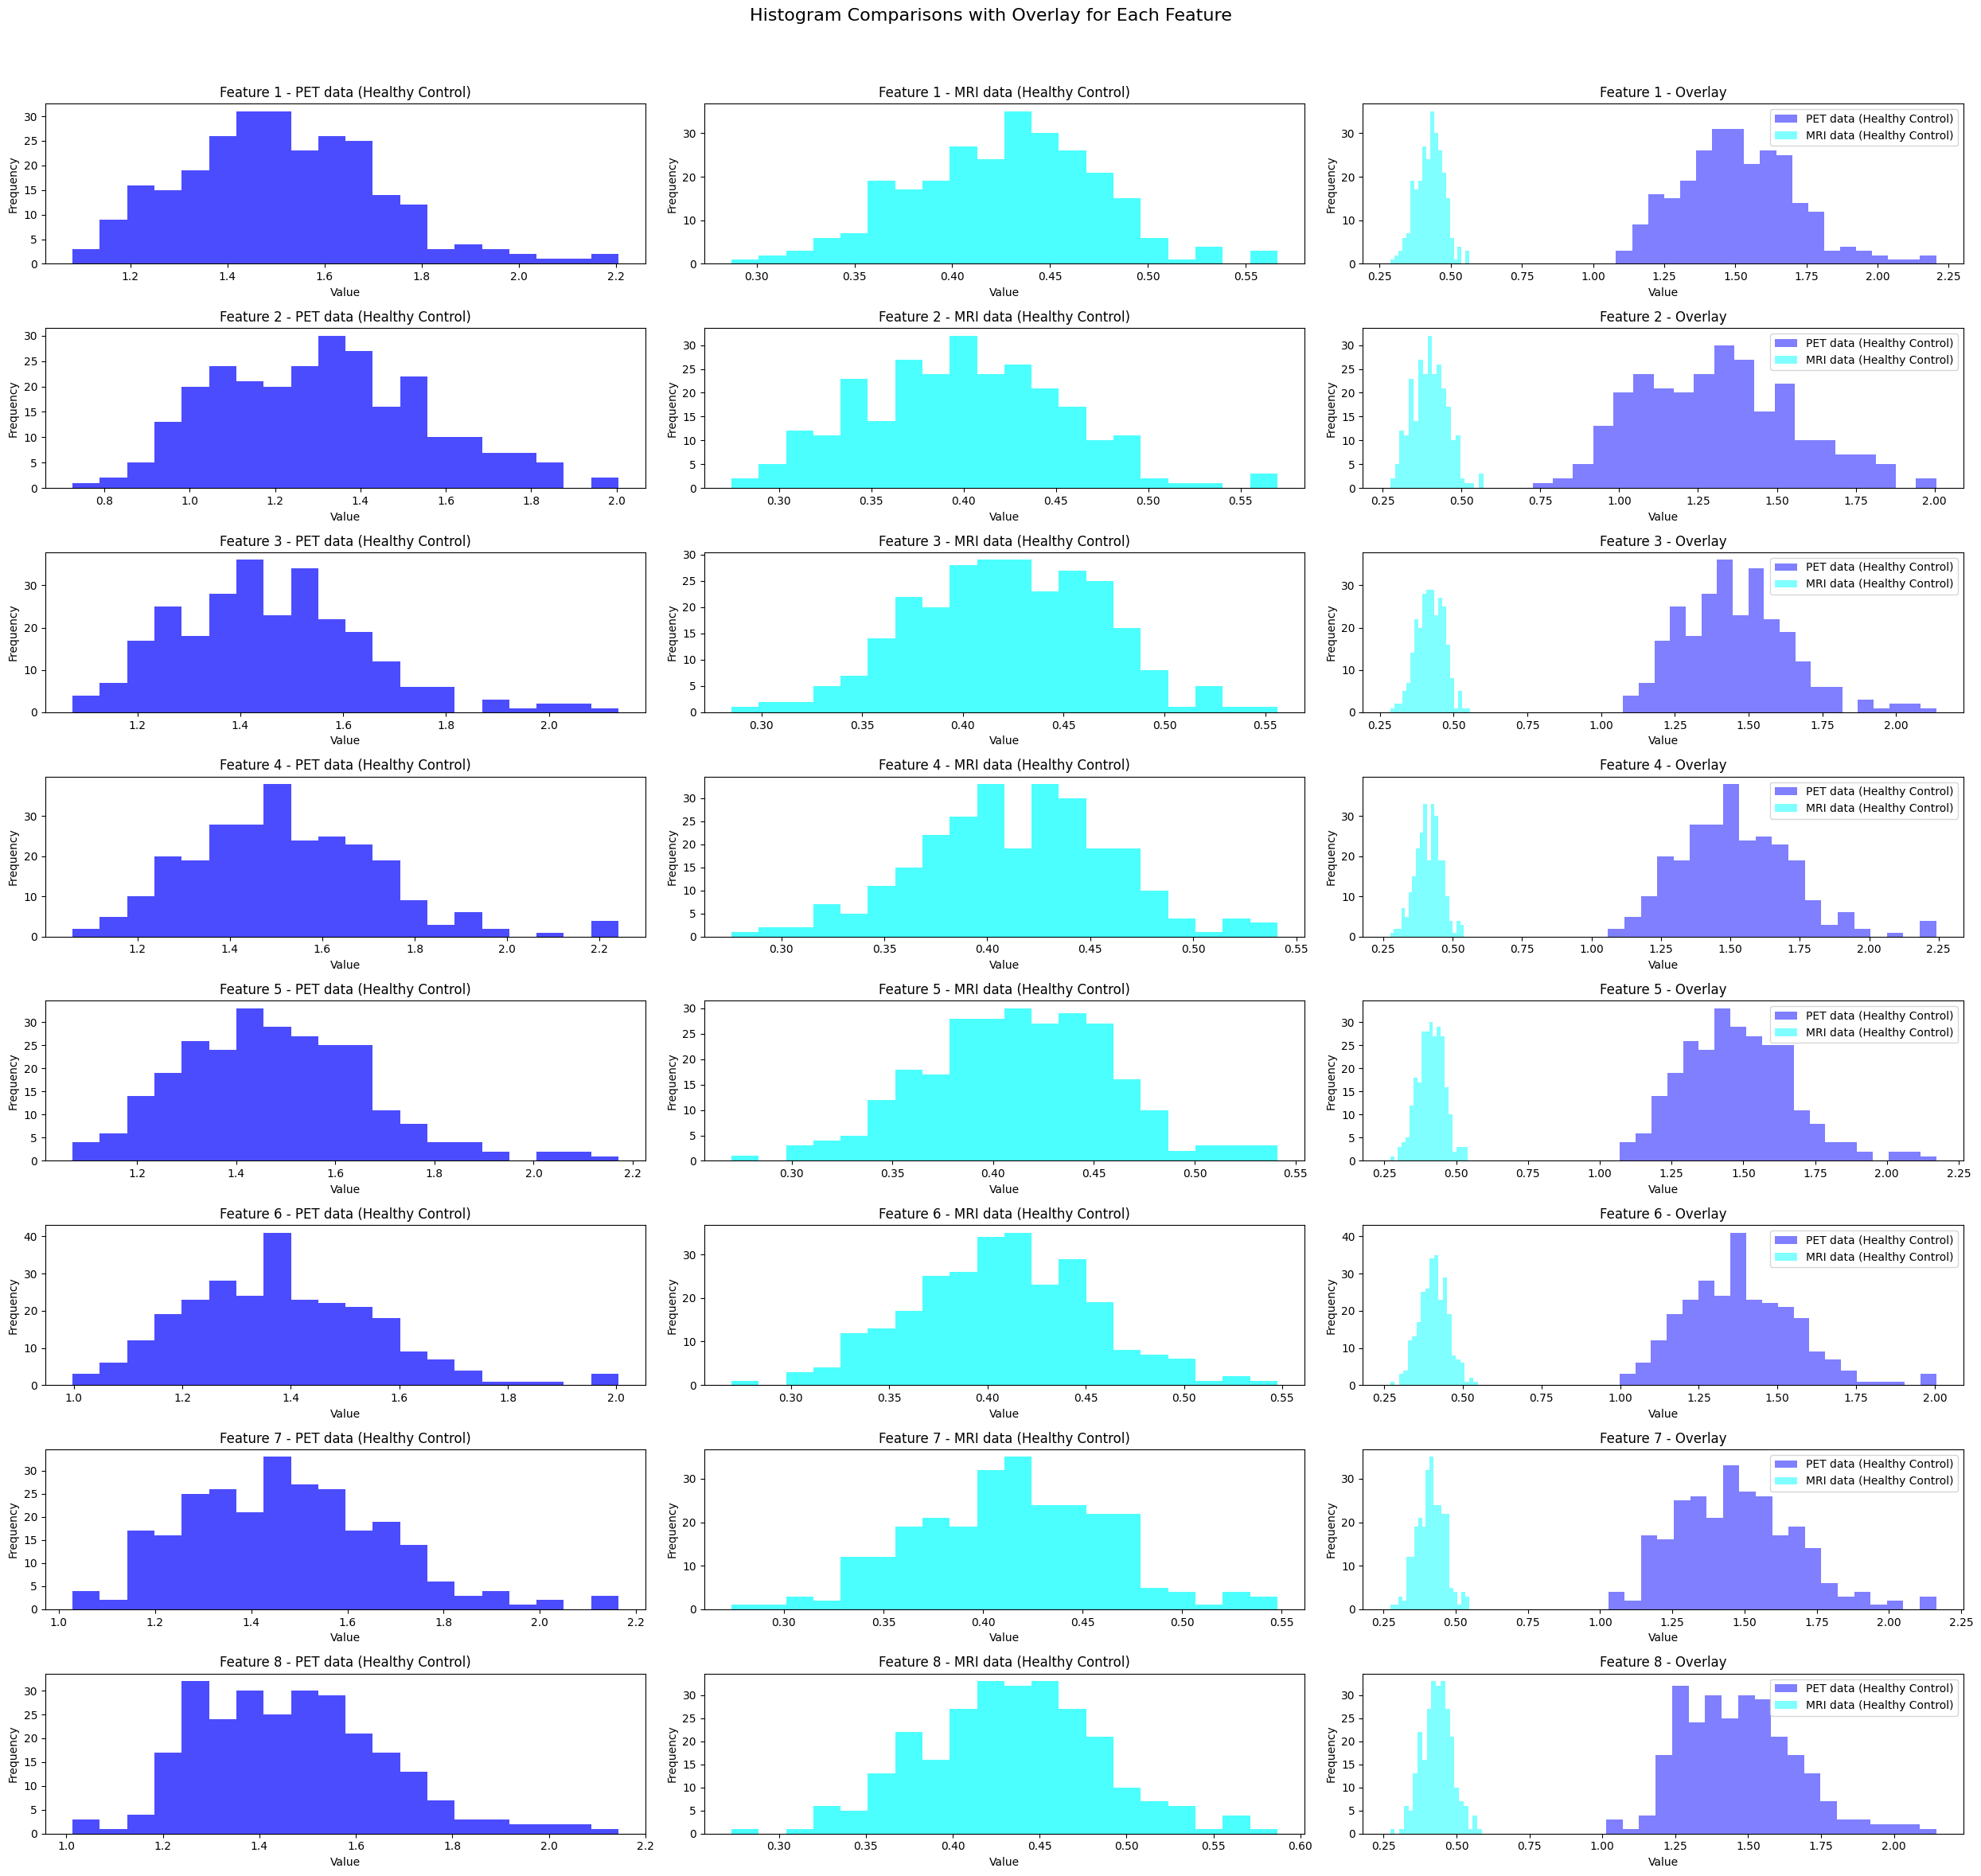

In [ ]:
title1="PET data (Healthy Control)"
title2= "MRI data (Healthy Control)"
plot_compare_histograms(X1_hc, X2_hc, title1, title2, selected_features)

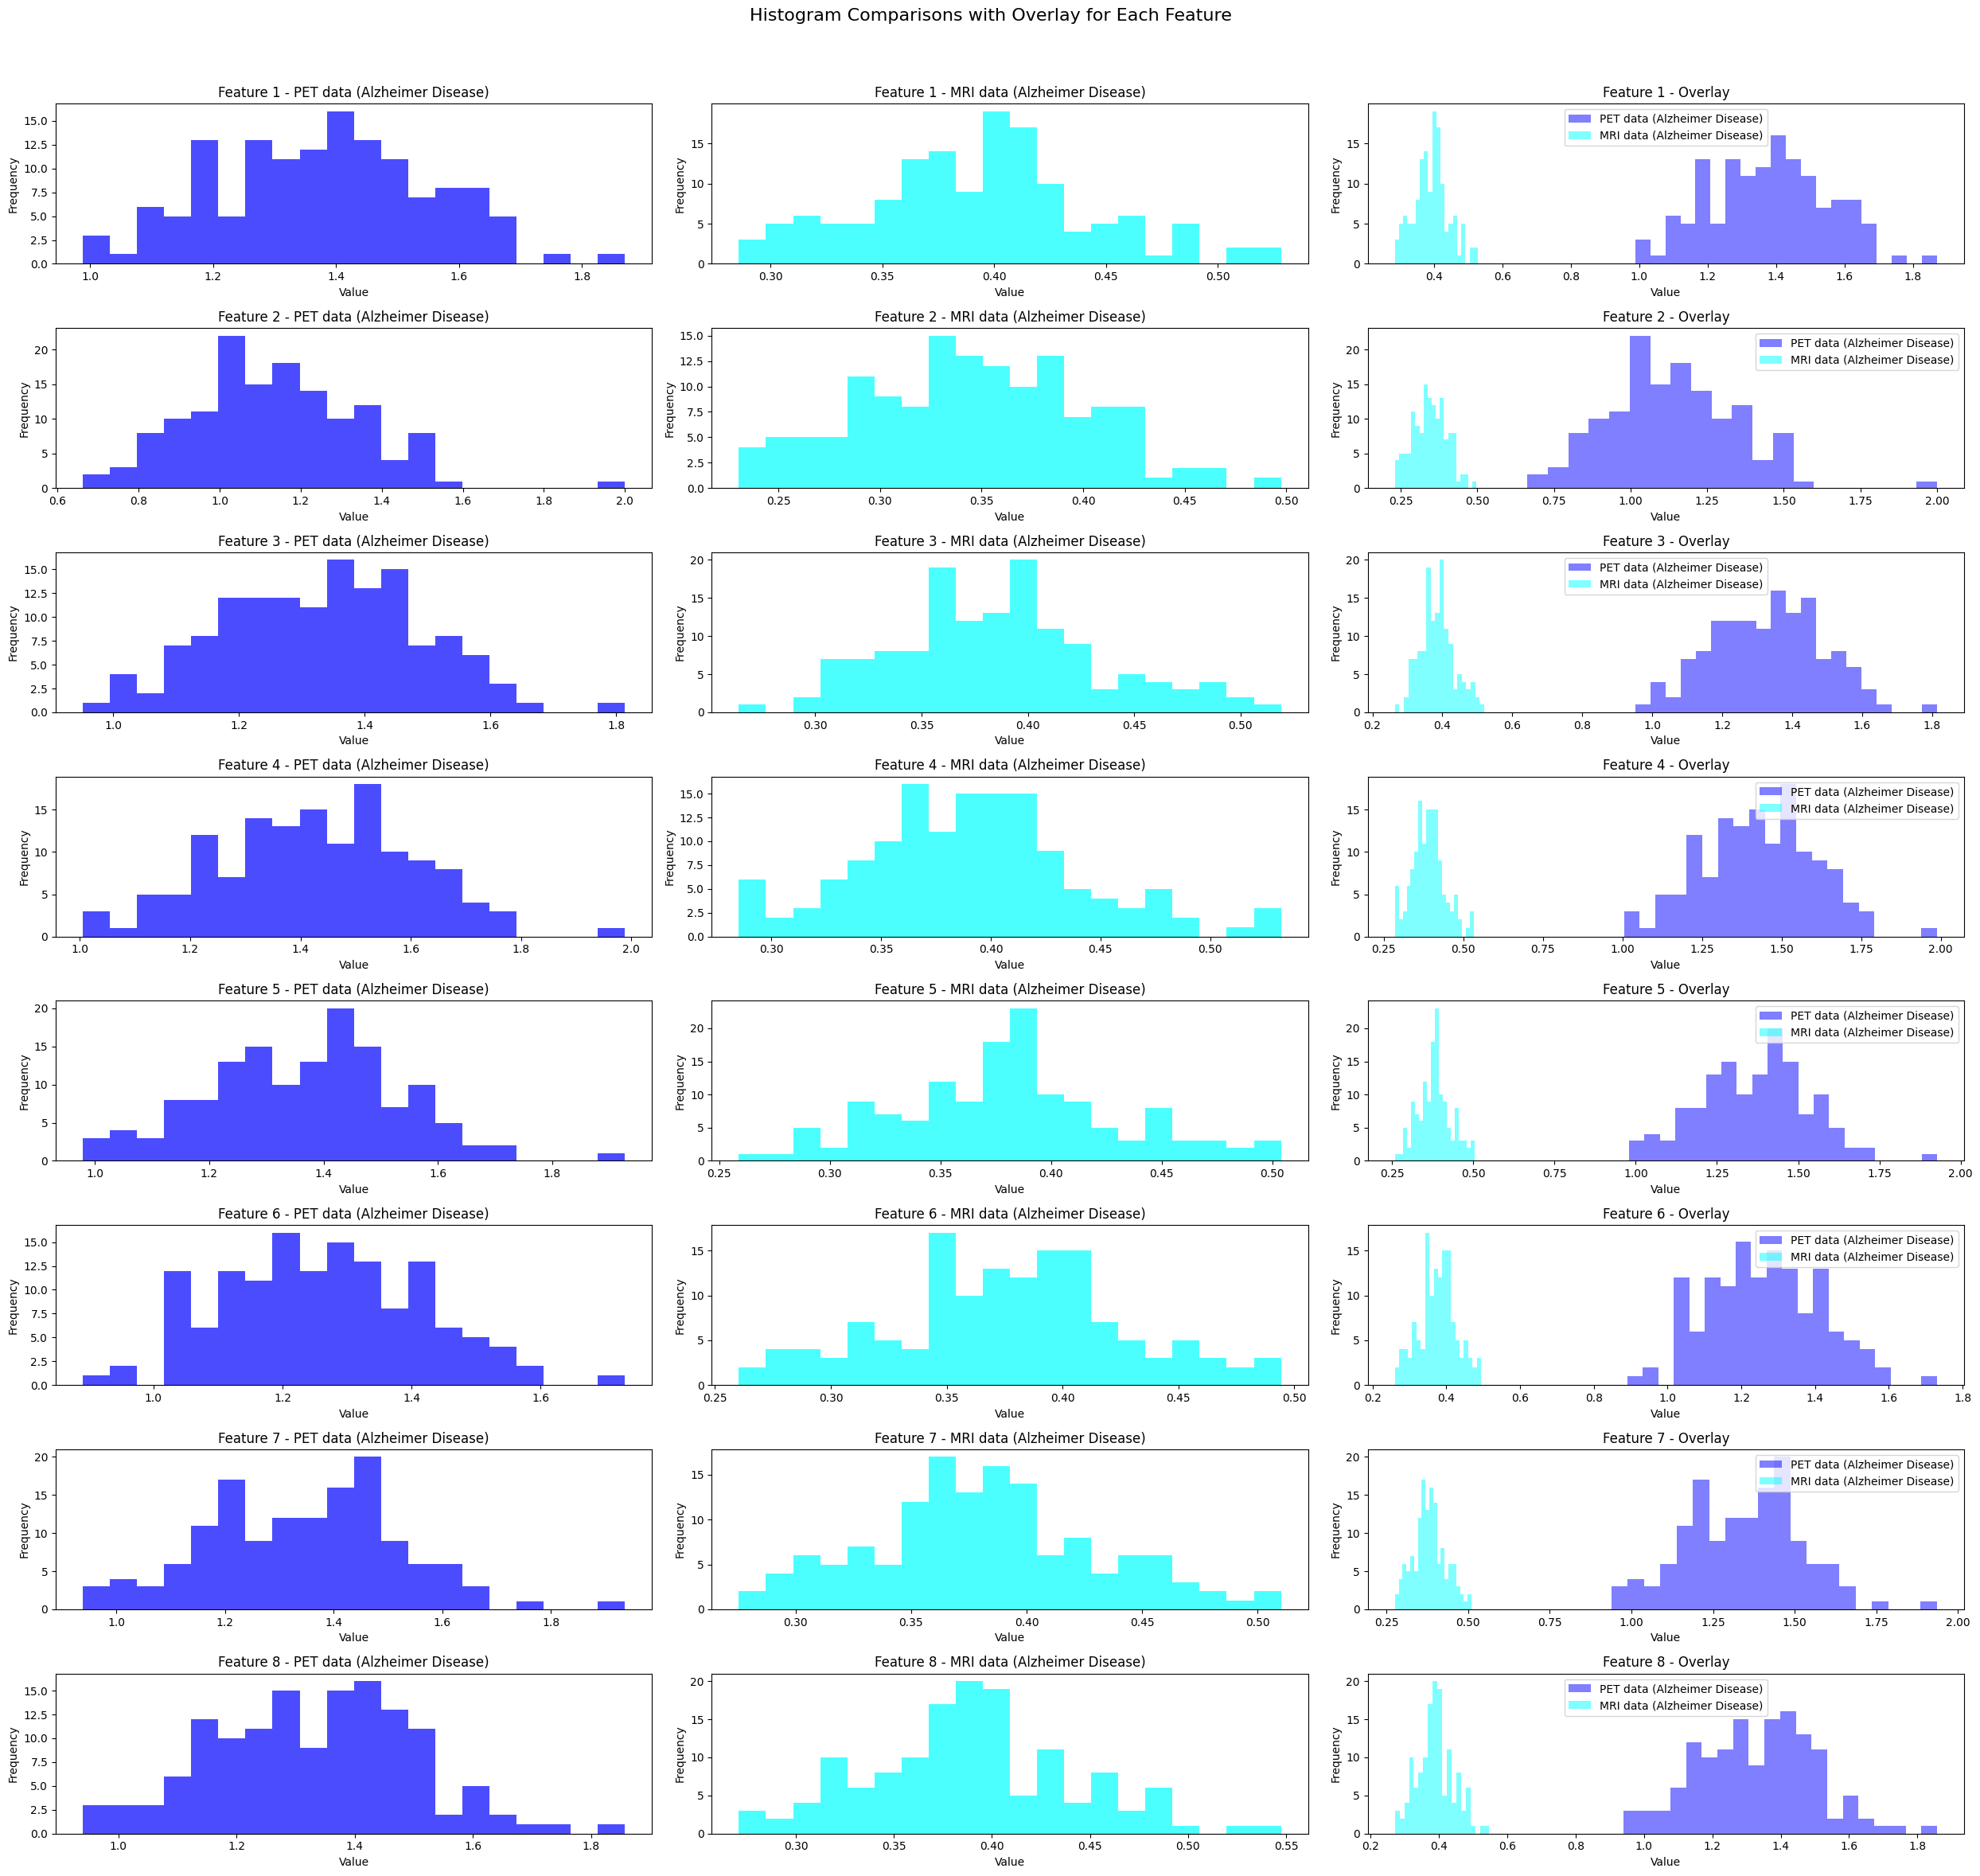

In [ ]:
title1="PET data (Alzheimer Disease)"
title2= "MRI data (Alzheimer Disease)"
plot_compare_histograms(X1_ad, X2_ad, title1, title2, selected_features)

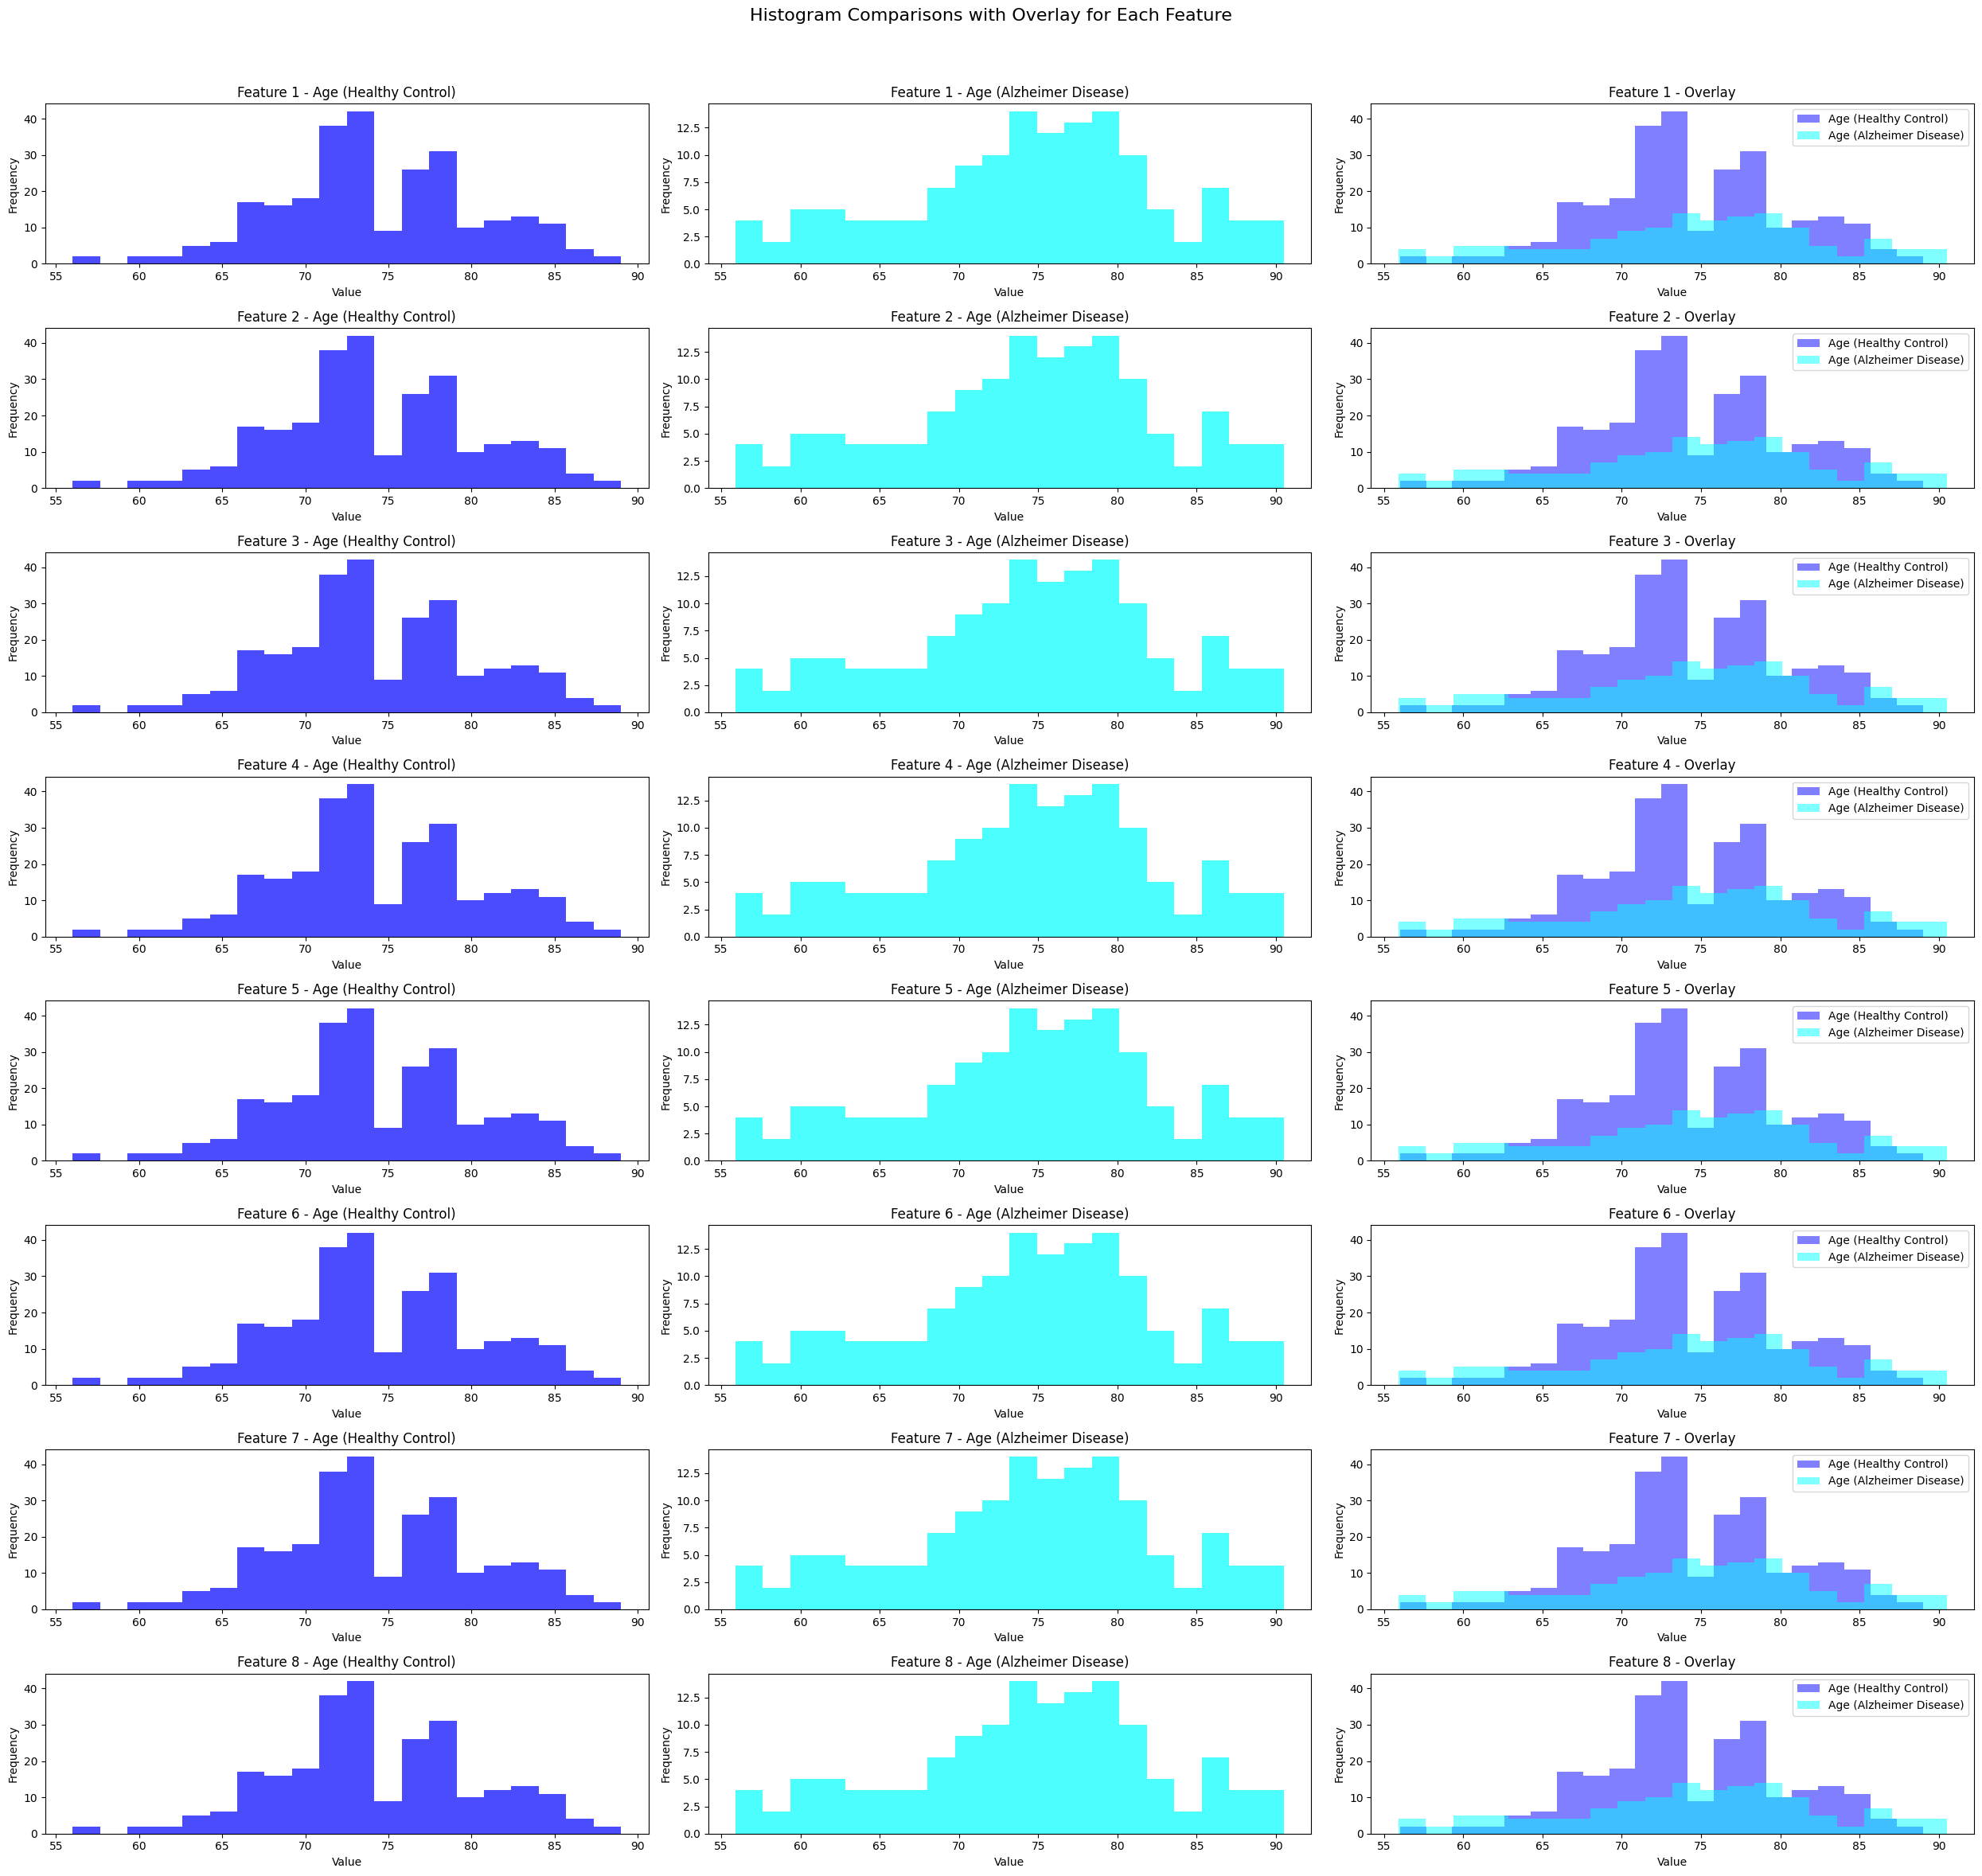

In [ ]:
hc_age = data_hc_modality1['Age'].values
ad_age = data_ad_modality1['Age'].values
title1= "Age (Healthy Control)"
title2= "Age (Alzheimer Disease)"
plot_compare_histograms(hc_age, ad_age, title1, title2, selected_features)

In [ ]:
def age_one_hot_encode(ages, min_age, max_age, step=5):
    bins = list(range(min_age, max_age + step, step))
    age_indices = np.digitize(ages, bins) - 1
    one_hot_encoded = np.eye(len(bins))[age_indices]
    return one_hot_encoded

In [ ]:
# Define min and max age
hc_age = data_hc_modality1['Age'].values
min_hc_age = int(np.min(hc_age))
max_hc_age = int(np.max(hc_age))
print(min_hc_age, max_hc_age)

# Define min and max age
ad_age = data_ad_modality1['Age'].values
min_ad_age = int(np.min(ad_age))
max_ad_age = int(np.max(ad_age))
print(min_ad_age, max_ad_age)

# Calculate Overal HC and AD min and max age
min_age = min(min_hc_age, min_ad_age)
max_age = max(max_hc_age, max_ad_age)
print(min_age, max_age)

56 89
55 90
55 90


In [ ]:
def sex_one_hot_encode(sex_array):
    return np.array([[1, 0] if sex == 'F' else [0, 1] for sex in sex_array])

In [ ]:
# Apply one-hot encoding
hc_age_one_hot = age_one_hot_encode(hc_age, min_age, max_age, step=5)
ad_age_one_hot = age_one_hot_encode(ad_age, min_age, max_age, step=5)

# Extract the 'Age' column
hc_sex = data_hc_modality1['Sex'].values
ad_sex = data_ad_modality1['Sex'].values
hc_sex_one_hot = sex_one_hot_encode(hc_sex)
ad_sex_one_hot = sex_one_hot_encode(ad_sex)

# Combine into final one-hot vector
demographic_features_hc = np.concatenate((hc_age_one_hot, hc_sex_one_hot), axis=1)
demographic_features_ad = np.concatenate((ad_age_one_hot, ad_sex_one_hot), axis=1)

# Convert to a PyTorch tensor
demo_hc_tensor = torch.tensor(demographic_features_hc, dtype=torch.float32)
demo_ad_tensor = torch.tensor(demographic_features_ad, dtype=torch.float32)

# Print shape to verify
print("One-hot encoded HC demo tensor shape:", demo_hc_tensor.shape)
print("One-hot encoded AD demo tensor shape:", demo_ad_tensor.shape)

# Print results
print(demo_hc_tensor)
print(demo_ad_tensor)

One-hot encoded HC demo tensor shape: torch.Size([266, 10])
One-hot encoded AD demo tensor shape: torch.Size([139, 10])
tensor([[0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.],
        [0., 0., 0.,  ..., 0., 1., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 1.],
        [1., 0., 0.,  ..., 0., 1., 0.],
        [0., 1., 0.,  ..., 0., 1., 0.]])
tensor([[0., 0., 0.,  ..., 0., 1., 0.],
        [1., 0., 0.,  ..., 0., 0., 1.],
        [0., 0., 1.,  ..., 0., 1., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 1.],
        [0., 1., 0.,  ..., 0., 0., 1.],
        [0., 0., 1.,  ..., 0., 0., 1.]])


In [ ]:
# Combine features with demographics
X1_hc_tensor = torch.tensor(X1_hc, dtype=torch.float32)
X2_hc_tensor = torch.tensor(X2_hc, dtype=torch.float32)
print(X1_hc_tensor.shape)
print(X2_hc_tensor.shape)

torch.Size([266, 116])
torch.Size([266, 116])


In [ ]:
print(X1_ad.shape)
print(X2_ad.shape)

(139, 116)
(139, 116)


In [ ]:
# MVAE model parameters
input_dim_1 = X1_hc_tensor.shape[1]
input_dim_2 = X2_hc_tensor.shape[1]
roi_dim = input_dim_1
demo_dim = demo_hc_tensor.shape[1]
print(demo_dim)
print(input_dim_1, input_dim_2)
latent_dim = 32
# batch_size = 32
batch_size = 1
epochs = 200
learning_rate = 1e-3
beta = 0.001

10
116 116


In [ ]:
# Define 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=False)

In [ ]:
# Training loop with 5-fold cross-validation
fold_train_losses = []
fold_test_losses = []
fold_train_losses_recon1 = []
fold_test_losses_recon1 = []
fold_train_losses_recon2 = []
fold_test_losses_recon2 = []

In [ ]:
# Train and calculate dij for each fold
for fold, (train_idx, test_idx) in enumerate(kfold.split(X1_hc_tensor)):
    print(f"Fold {fold + 1}")

    # Split Healthy Control data into train and validation sets
    train_X1 = X1_hc_tensor[train_idx]
    test_X1 = X1_hc_tensor[test_idx]
    train_X2 = X2_hc_tensor[train_idx]
    test_X2 = X2_hc_tensor[test_idx]
    train_demo = demo_hc_tensor[train_idx]
    test_demo = demo_hc_tensor[test_idx]

    train_loader = DataLoader(TensorDataset(train_X1, train_X2, train_demo), batch_size = batch_size, shuffle = False)
    test_loader = DataLoader(TensorDataset(test_X1, test_X2, test_demo), batch_size = batch_size, shuffle = False)

    # Initialize the model for each fold
    model = CVAE(input_dim_1, input_dim_2, demo_dim, latent_dim)
    optimizer = optim.Adam(model.parameters(), lr = learning_rate)

    train_loss_history = []
    train_loss_recon1_history = []
    train_loss_recon2_history = []

    test_loss_history = []
    test_loss_recon1_history = []
    test_loss_recon2_history = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        train_loss_recon_1 = 0.0
        train_loss_recon_2 = 0.0
        for batch1, batch2, batch_demo in train_loader:
            optimizer.zero_grad()
            recon_1, recon_2, mu, logvar = model(batch1, batch2, batch_demo)
            loss = cvae_loss(recon_1, recon_2, batch1, batch2, mu, logvar, beta)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            loss_recon_1, loss_recon_2 = loss_recon1_recon2(recon_1, recon_2, batch1, batch2, mu, logvar)
            train_loss_recon_1 += loss_recon_1.item()
            train_loss_recon_2 += loss_recon_2.item()

        train_loss /= len(train_loader.dataset)
        train_loss_recon_1 /= len(train_loader.dataset)
        train_loss_recon_2 /= len(train_loader.dataset)
        train_loss_history.append(train_loss)
        train_loss_recon1_history.append(train_loss_recon_1)
        train_loss_recon2_history.append(train_loss_recon_2)

        model.eval()
        test_loss = 0.0
        test_loss_recon_1 = 0.0
        test_loss_recon_2 = 0.0
        with torch.no_grad():
            for batch1, batch2, batch_demo in test_loader:
                recon_1, recon_2, mu, logvar = model(batch1, batch2, batch_demo)
                loss = cvae_loss(recon_1, recon_2, batch1, batch2, mu, logvar, beta)
                test_loss += loss.item()
                loss_recon_1, loss_recon_2 = loss_recon1_recon2(recon_1, recon_2, batch1, batch2, mu, logvar)
                test_loss_recon_1 += loss_recon_1.item()
                test_loss_recon_2 += loss_recon_2.item()

            test_loss /= len(test_loader.dataset)
            test_loss_recon_1 /= len(test_loader.dataset)
            test_loss_recon_2 /= len(test_loader.dataset)
            test_loss_history.append(test_loss)
            test_loss_recon1_history.append(test_loss_recon_1)
            test_loss_recon2_history.append(test_loss_recon_2)

        print(f"Epoch {epoch + 1}/{epochs} - Train Loss: {train_loss:.4f}, Test Loss: {test_loss:.4f}")
        print(f"Epoch {epoch + 1}/{epochs} - Train Loss Recon1: {train_loss_recon_1:.4f}, Test Loss Recon1: {test_loss_recon_1:.4f}")
        print(f"Epoch {epoch + 1}/{epochs} - Train Loss Recon2: {train_loss_recon_2:.4f}, Test Loss Recon2: {test_loss_recon_2:.4f}")

    fold_train_losses.append(train_loss_history)
    fold_train_losses_recon1.append(train_loss_recon1_history)
    fold_train_losses_recon2.append(train_loss_recon2_history)
    fold_test_losses.append(test_loss_history)
    fold_test_losses_recon1.append(test_loss_recon1_history)
    fold_test_losses_recon2.append(test_loss_recon2_history)


Fold 1
Epoch 1/200 - Train Loss: 0.2747, Test Loss: 0.0225
Epoch 1/200 - Train Loss Recon1: 0.2500, Test Loss Recon1: 0.0165
Epoch 1/200 - Train Loss Recon2: 0.0237, Test Loss Recon2: 0.0046
Epoch 2/200 - Train Loss: 0.0185, Test Loss: 0.0145
Epoch 2/200 - Train Loss Recon1: 0.0120, Test Loss Recon1: 0.0093
Epoch 2/200 - Train Loss Recon2: 0.0048, Test Loss Recon2: 0.0033
Epoch 3/200 - Train Loss: 0.0151, Test Loss: 0.0127
Epoch 3/200 - Train Loss Recon1: 0.0100, Test Loss Recon1: 0.0085
Epoch 3/200 - Train Loss Recon2: 0.0030, Test Loss Recon2: 0.0019
Epoch 4/200 - Train Loss: 0.0121, Test Loss: 0.0110
Epoch 4/200 - Train Loss Recon1: 0.0081, Test Loss Recon1: 0.0073
Epoch 4/200 - Train Loss Recon2: 0.0017, Test Loss Recon2: 0.0013
Epoch 5/200 - Train Loss: 0.0110, Test Loss: 0.0099
Epoch 5/200 - Train Loss Recon1: 0.0073, Test Loss Recon1: 0.0066
Epoch 5/200 - Train Loss Recon2: 0.0014, Test Loss Recon2: 0.0009
Epoch 6/200 - Train Loss: 0.0109, Test Loss: 0.0101
Epoch 6/200 - Train L

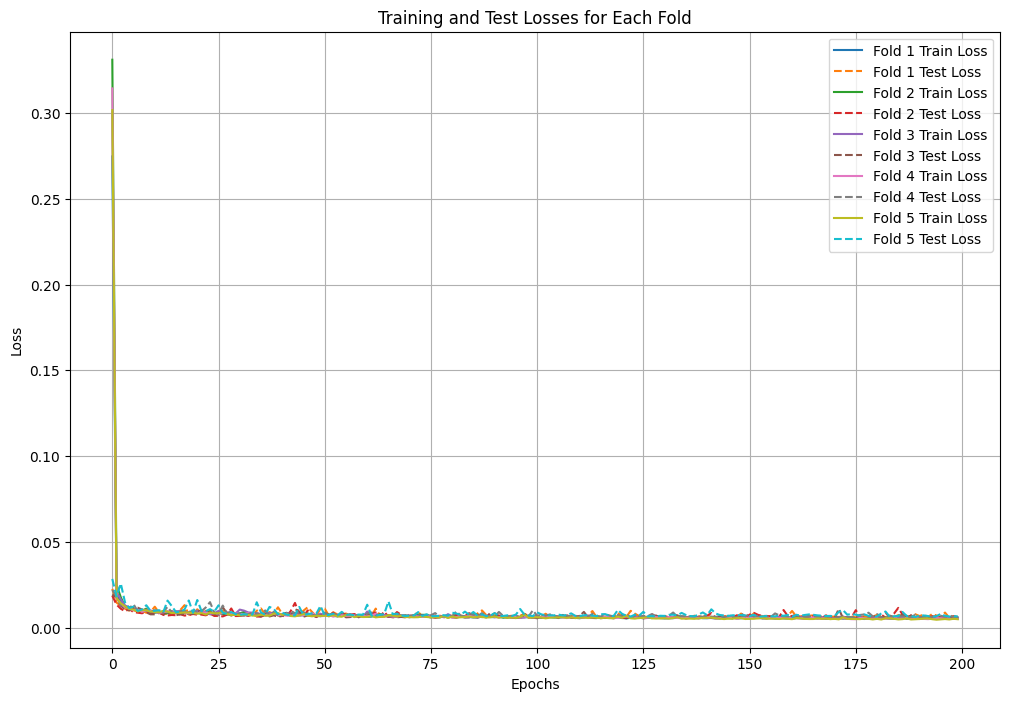

In [ ]:
# Plot training and test losses for each fold
plt.figure(figsize=(12, 8))
for fold in range(5):
    plt.plot(fold_train_losses[fold], label=f'Fold {fold + 1} Train Loss')
    plt.plot(fold_test_losses[fold], label=f'Fold {fold + 1} Test Loss', linestyle='--')

plt.title("Training and Test Losses for Each Fold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

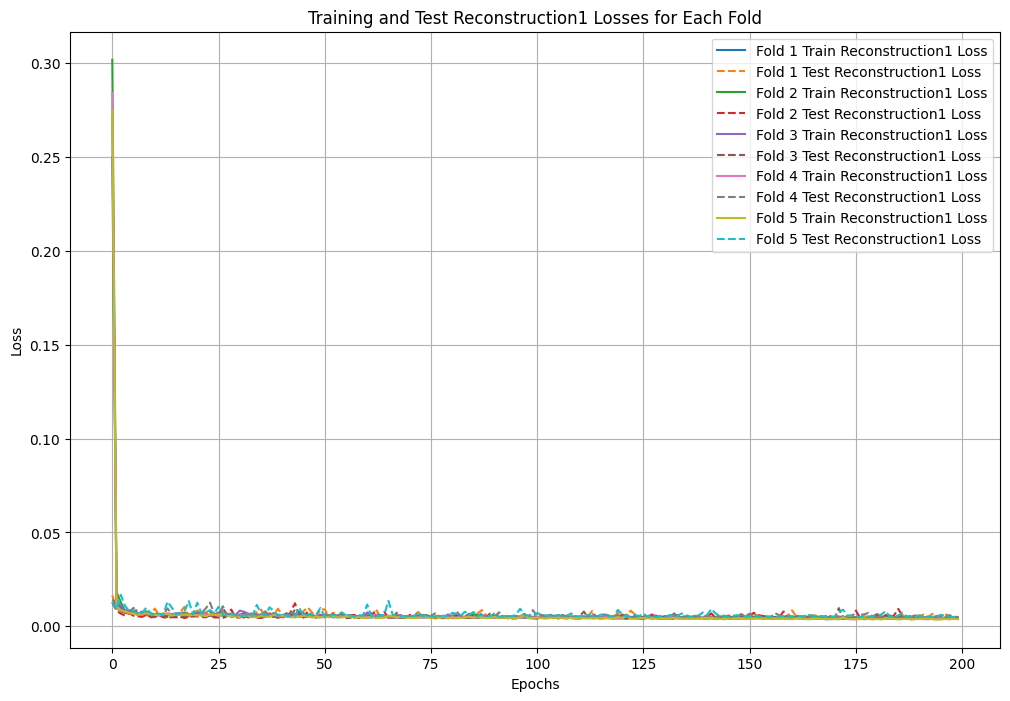

In [ ]:
# Plot training and test losses for each fold
plt.figure(figsize=(12, 8))
for fold in range(5):
    plt.plot(fold_train_losses_recon1[fold], label=f'Fold {fold + 1} Train Reconstruction1 Loss')
    plt.plot(fold_test_losses_recon1[fold], label=f'Fold {fold + 1} Test Reconstruction1 Loss', linestyle='--')

plt.title("Training and Test Reconstruction1 Losses for Each Fold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

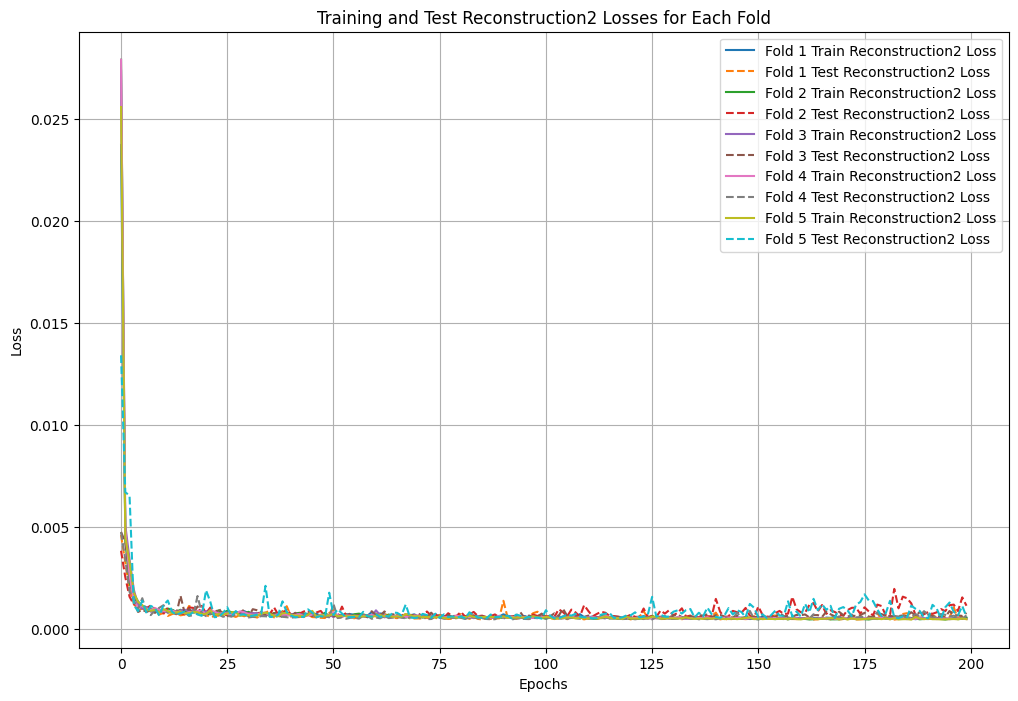

In [ ]:
# Plot training and test losses for each fold
plt.figure(figsize=(12, 8))
for fold in range(5):
    plt.plot(fold_train_losses_recon2[fold], label=f'Fold {fold + 1} Train Reconstruction2 Loss')
    plt.plot(fold_test_losses_recon2[fold], label=f'Fold {fold + 1} Test Reconstruction2 Loss', linestyle='--')

plt.title("Training and Test Reconstruction2 Losses for Each Fold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

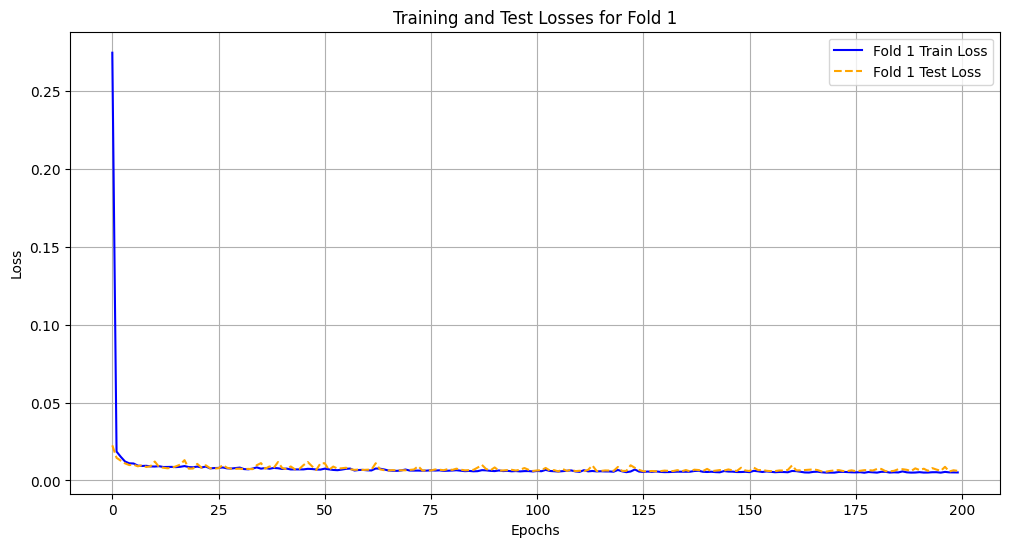

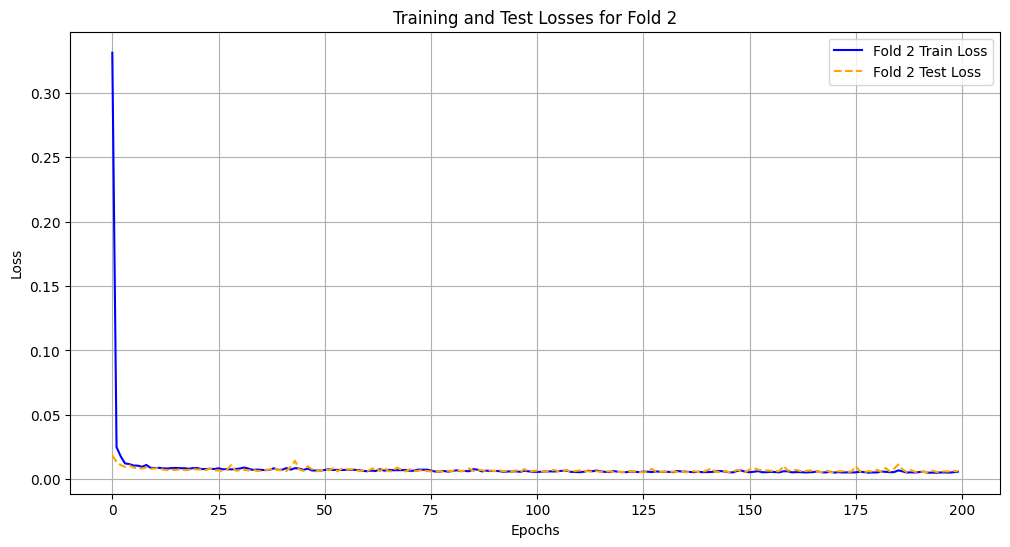

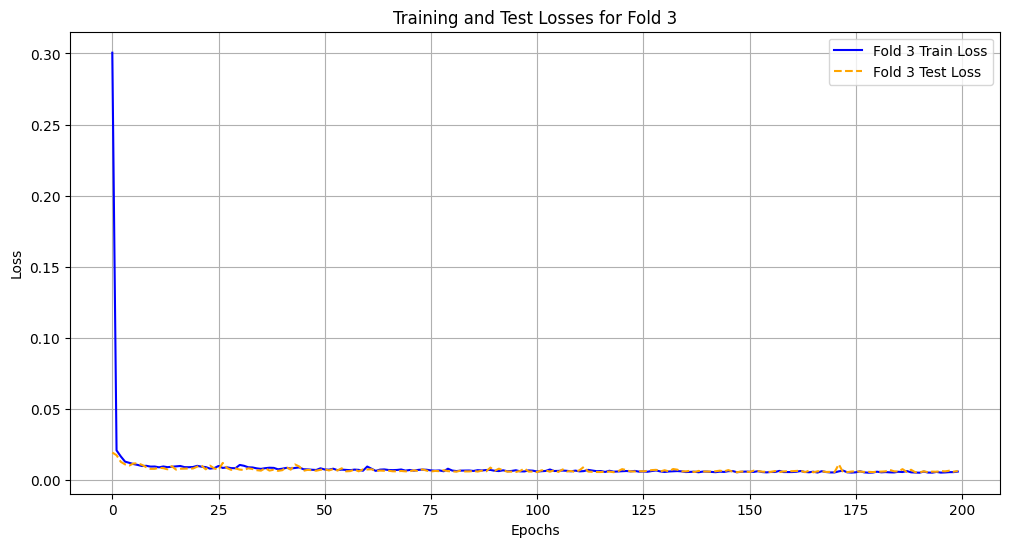

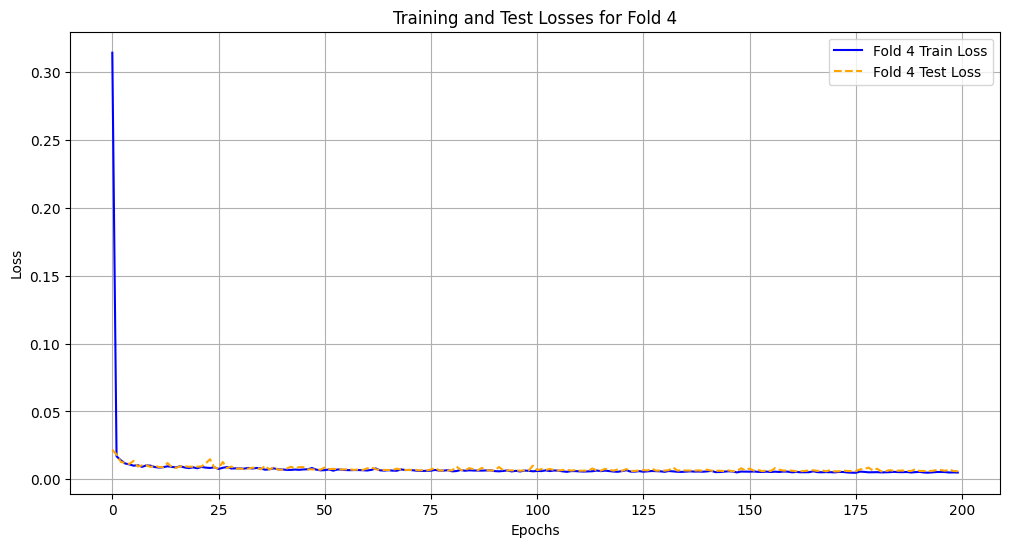

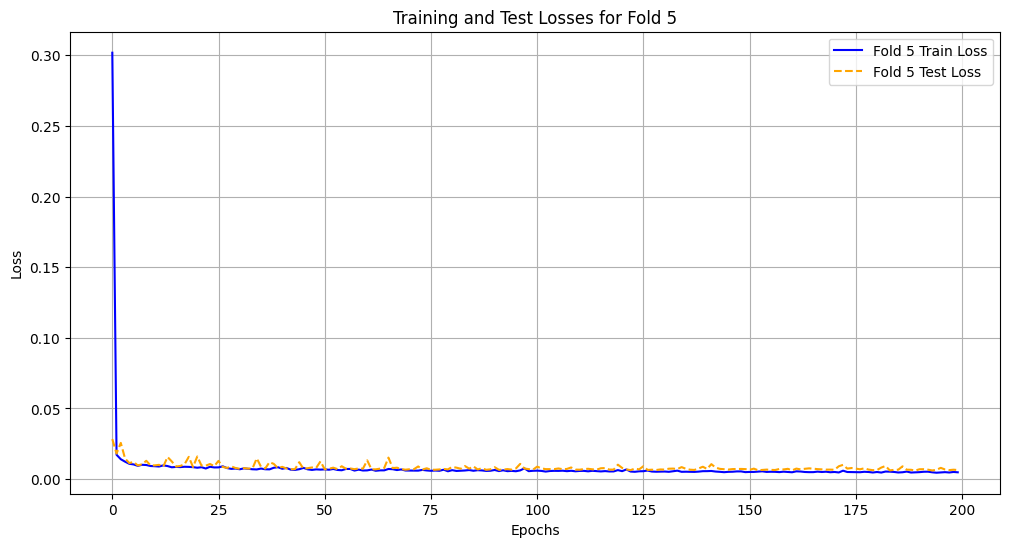

In [ ]:
# Plot training and test losses for each fold
for fold in range(5):
    plt.figure(figsize=(12, 6))
    plt.plot(fold_train_losses[fold], label=f'Fold {fold + 1} Train Loss', color='blue')
    plt.plot(fold_test_losses[fold], label=f'Fold {fold + 1} Test Loss', color='orange', linestyle='--')
    plt.title(f"Training and Test Losses for Fold {fold + 1}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

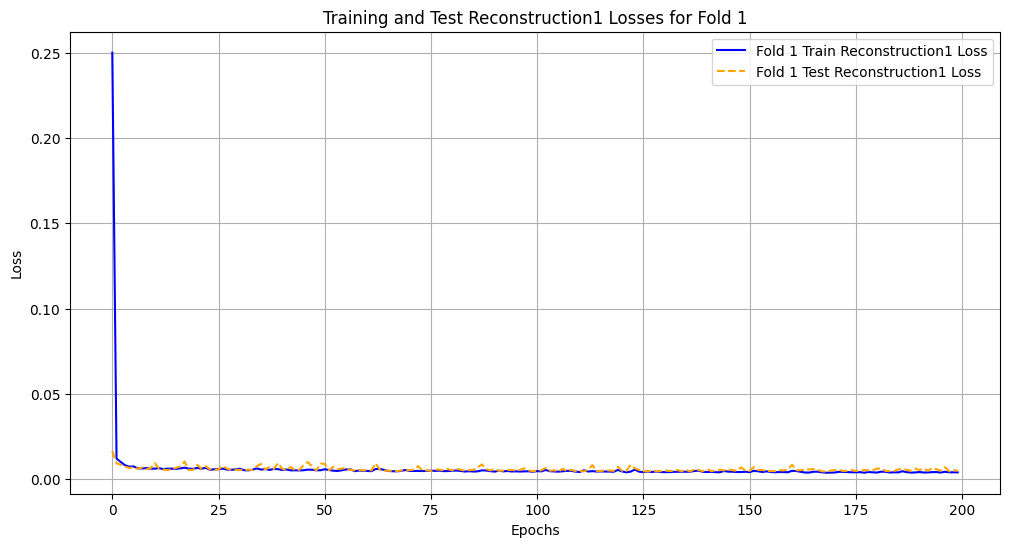

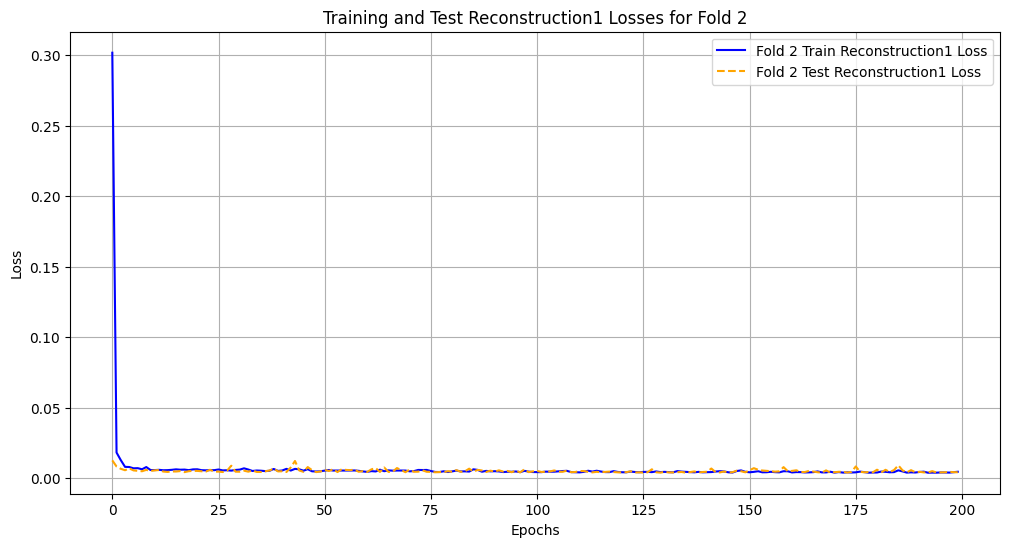

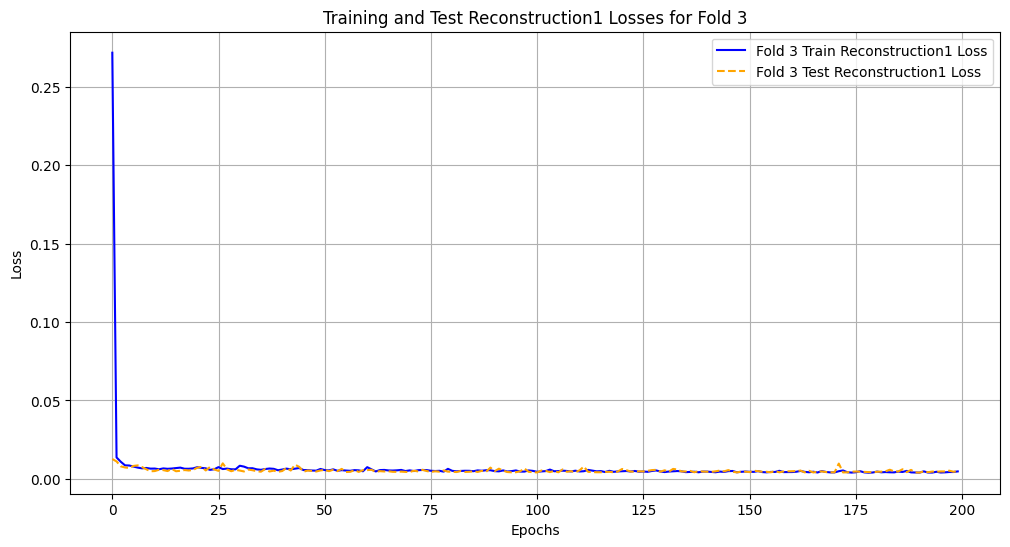

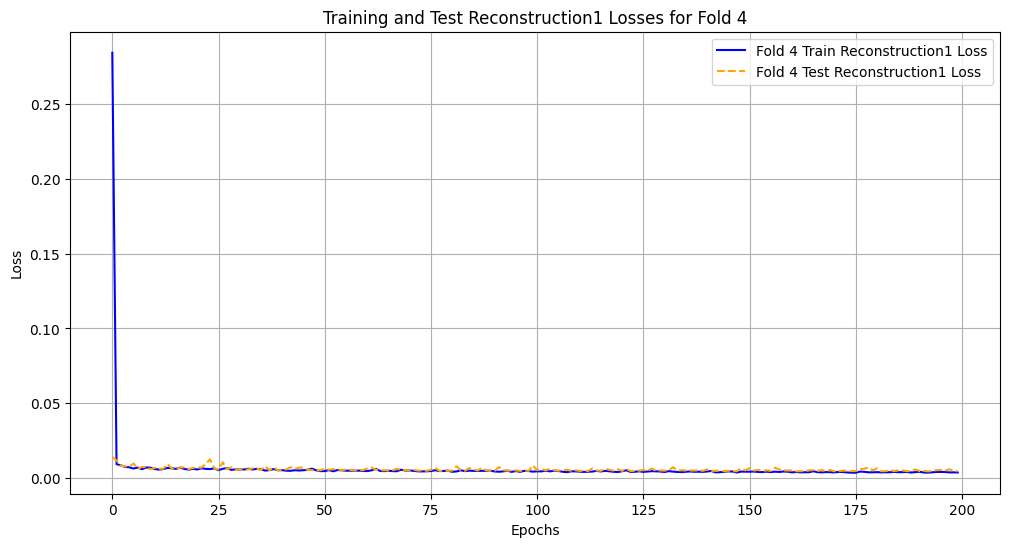

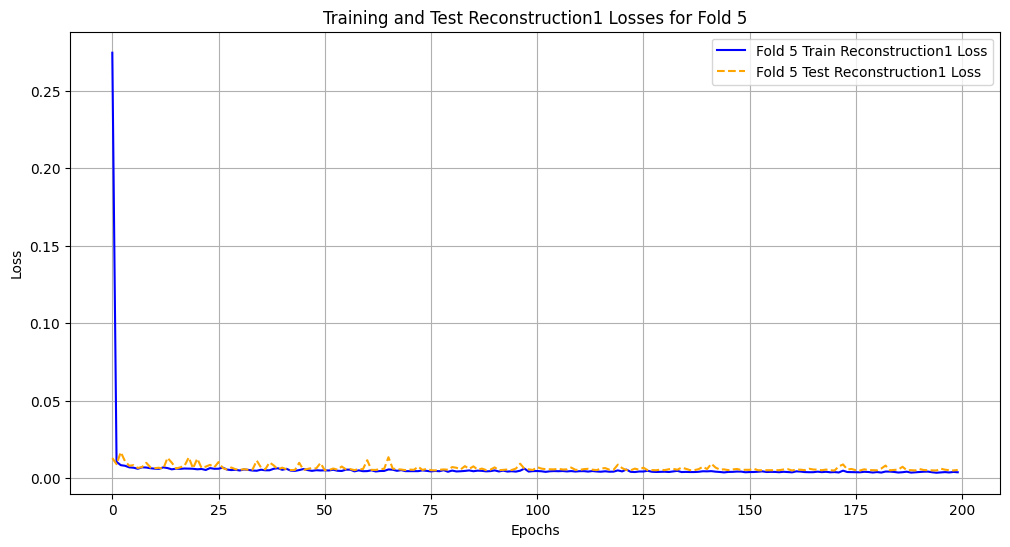

In [ ]:
# Plot training and test losses for each fold
for fold in range(5):
    plt.figure(figsize=(12, 6))
    plt.plot(fold_train_losses_recon1[fold], label=f'Fold {fold + 1} Train Reconstruction1 Loss', color='blue')
    plt.plot(fold_test_losses_recon1[fold], label=f'Fold {fold + 1} Test Reconstruction1 Loss', color='orange', linestyle='--')
    plt.title(f"Training and Test Reconstruction1 Losses for Fold {fold + 1}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

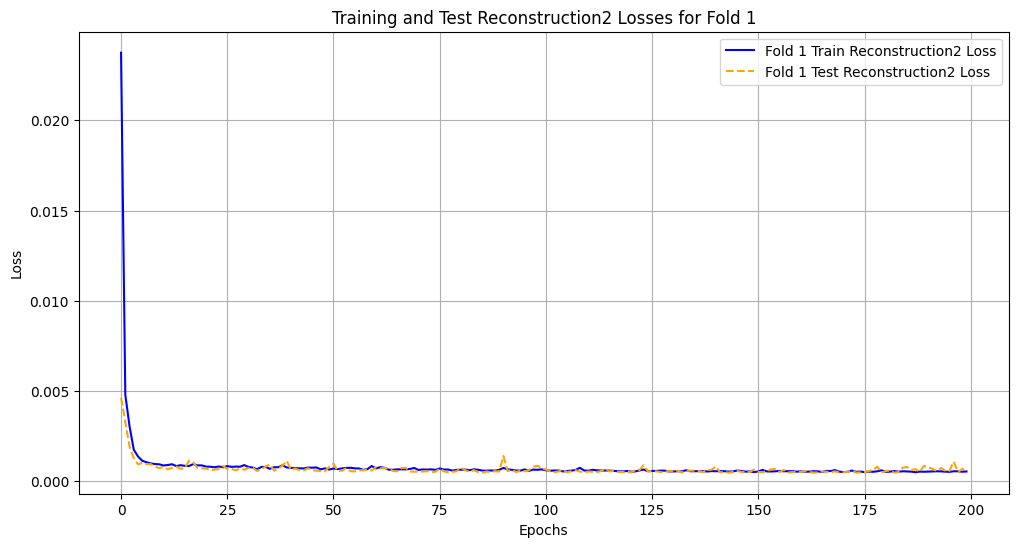

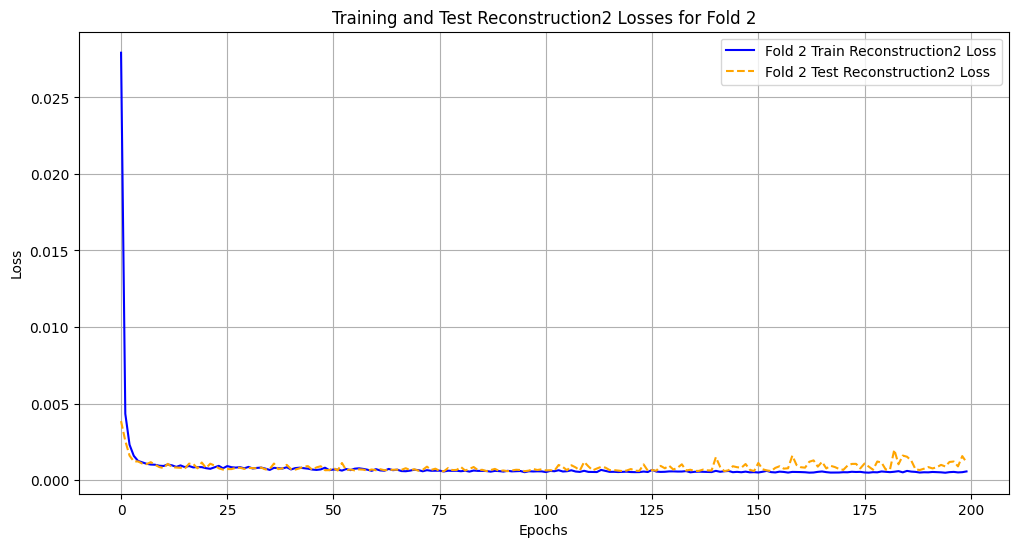

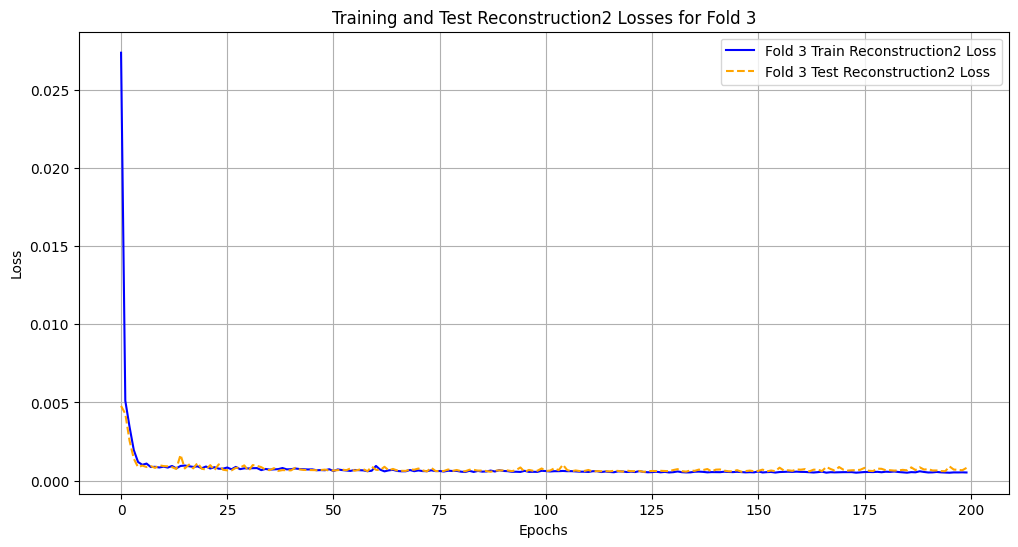

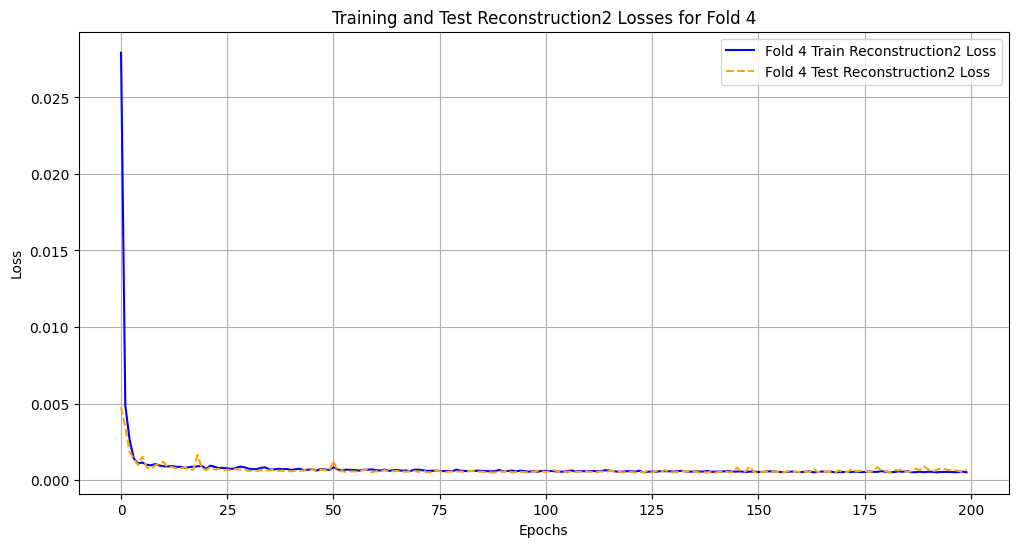

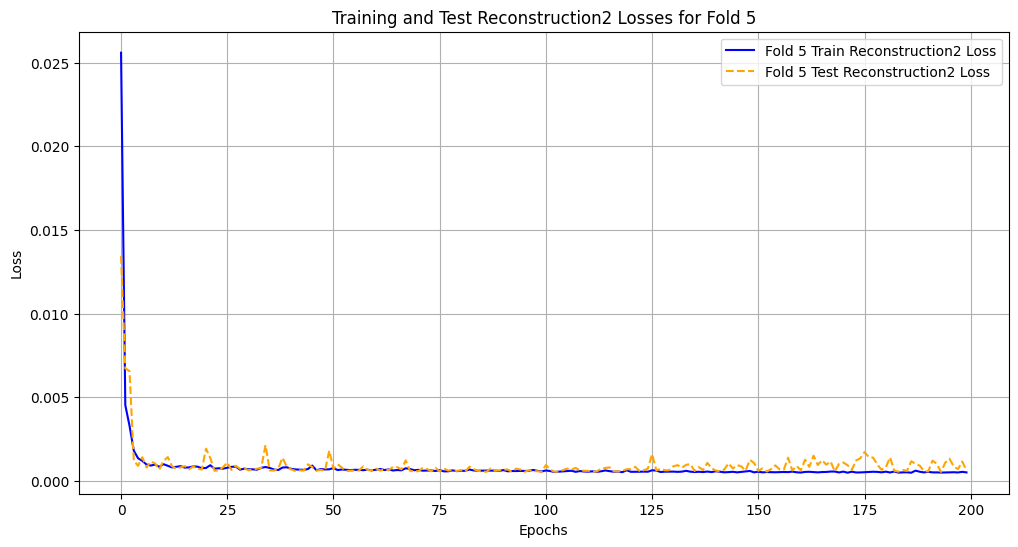

In [ ]:
# Plot training and test losses for each fold
for fold in range(5):
    plt.figure(figsize=(12, 6))
    plt.plot(fold_train_losses_recon2[fold], label=f'Fold {fold + 1} Train Reconstruction2 Loss', color='blue')
    plt.plot(fold_test_losses_recon2[fold], label=f'Fold {fold + 1} Test Reconstruction2 Loss', color='orange', linestyle='--')
    plt.title(f"Training and Test Reconstruction2 Losses for Fold {fold + 1}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
# Healthy Control data (fixed for evaluating)
X1_valmod_hc_tensor = torch.tensor(X1_hc, dtype=torch.float32)
X2_valmod_hc_tensor = torch.tensor(X2_hc, dtype=torch.float32)
#demo_hc_tensor = torch.tensor(demographic_features_hc, dtype=torch.float32)

# Patient data (fixed for evaluating)
X1_valmod_ad_tensor = torch.tensor(X1_ad, dtype=torch.float32)
X2_valmod_ad_tensor = torch.tensor(X2_ad, dtype=torch.float32)
#demo_hc_tensor = torch.tensor(demographic_features_hc, dtype=torch.float32)

# Using MAE to show differences

In [ ]:
model.eval()
with torch.no_grad():
    # Reconstruct
    recon_hc_m1, recon_hc_m2, _, _ = model(X1_valmod_hc_tensor, X2_valmod_hc_tensor, demo_hc_tensor)
    recon_ad_m1, recon_ad_m2, _, _ = model(X1_valmod_ad_tensor, X2_valmod_ad_tensor, demo_ad_tensor)

    # 🔹 Mean Absolute Error (MAE)
    M1_diff_hc = F.l1_loss(X1_valmod_hc_tensor, recon_hc_m1, reduction='none')
    M2_diff_hc = F.l1_loss(X2_valmod_hc_tensor, recon_hc_m2, reduction='none')
    M1_diff_ad = F.l1_loss(X1_valmod_ad_tensor, recon_ad_m1, reduction='none')
    M2_diff_ad = F.l1_loss(X2_valmod_ad_tensor, recon_ad_m2, reduction='none')


# Obtaining shapes and other properties of Data

In [ ]:
print(f"Shape of X1_valmod_hc_tensor: {X1_valmod_hc_tensor.shape}")
print(f"Shape of X2_valmod_hc_tensor: {X2_valmod_hc_tensor.shape}")
print(f"Shape of X1_valmod_ad_tensor: {X1_valmod_ad_tensor.shape}")
print(f"Shape of X2_valmod_ad_tensor: {X2_valmod_ad_tensor.shape}")

Shape of X1_valmod_hc_tensor: torch.Size([266, 116])
Shape of X2_valmod_hc_tensor: torch.Size([266, 116])
Shape of X1_valmod_ad_tensor: torch.Size([139, 116])
Shape of X2_valmod_ad_tensor: torch.Size([139, 116])


In [ ]:
print(f"Shape of recon_hc_m1: {recon_hc_m1.shape}")
print(f"Shape of recon_hc_m2: {recon_hc_m2.shape}")
print(f"Shape of recon_ad_m1: {recon_ad_m1.shape}")
print(f"Shape of recon_ad_m2: {recon_ad_m2.shape}")

Shape of recon_hc_m1: torch.Size([266, 116])
Shape of recon_hc_m2: torch.Size([266, 116])
Shape of recon_ad_m1: torch.Size([139, 116])
Shape of recon_ad_m2: torch.Size([139, 116])


In [ ]:
print(f"Shape of M1_diff_hc: {M1_diff_hc.shape}")
print(f"Shape of M2_diff_hc: {M2_diff_hc.shape}")
print(f"Shape of M1_diff_ad: {M1_diff_ad.shape}")
print(f"Shape of M2_diff_ad: {M2_diff_ad.shape}")

Shape of M1_diff_hc: torch.Size([266, 116])
Shape of M2_diff_hc: torch.Size([266, 116])
Shape of M1_diff_ad: torch.Size([139, 116])
Shape of M2_diff_ad: torch.Size([139, 116])


In [ ]:
print(X1_valmod_hc_tensor)

tensor([[1.3730, 1.3622, 1.2824,  ..., 0.7771, 1.4465, 0.8511],
        [1.7570, 1.8534, 1.6331,  ..., 0.8532, 1.7037, 0.9907],
        [1.4665, 1.3880, 1.3847,  ..., 0.8184, 1.5108, 0.8164],
        ...,
        [1.2566, 1.0252, 1.2429,  ..., 0.7799, 1.2936, 0.8838],
        [1.6463, 1.7193, 1.6186,  ..., 0.7951, 1.7200, 1.4393],
        [1.6580, 1.4632, 1.6566,  ..., 0.8904, 1.7487, 1.6282]])


In [ ]:
print(X2_valmod_hc_tensor)

tensor([[0.4402, 0.3941, 0.4431,  ..., 0.0046, 0.4440, 0.3084],
        [0.5562, 0.5552, 0.5560,  ..., 0.0465, 0.5319, 0.4088],
        [0.4016, 0.3465, 0.3978,  ..., 0.0123, 0.3769, 0.3101],
        ...,
        [0.4536, 0.4302, 0.4666,  ..., 0.0118, 0.4813, 0.3258],
        [0.4629, 0.4278, 0.4594,  ..., 0.0117, 0.4758, 0.3664],
        [0.4348, 0.4240, 0.4393,  ..., 0.0103, 0.4931, 0.4225]])


In [ ]:
print(X1_valmod_ad_tensor)

tensor([[1.3270, 1.0260, 1.3680,  ..., 0.8230, 1.3865, 0.5914],
        [1.3426, 1.1349, 1.3435,  ..., 0.7954, 1.4012, 0.6210],
        [1.5043, 1.3516, 1.4474,  ..., 0.8611, 1.5723, 0.7459],
        ...,
        [1.5337, 1.1839, 1.4874,  ..., 0.9062, 1.6081, 0.8012],
        [1.4233, 1.2740, 1.3793,  ..., 0.7901, 1.4664, 0.8210],
        [1.3732, 1.2398, 1.4091,  ..., 0.9527, 1.5286, 0.6604]])


In [ ]:
print(X2_valmod_ad_tensor)

tensor([[0.4855, 0.4103, 0.4831,  ..., 0.0039, 0.3846, 0.1332],
        [0.4386, 0.3559, 0.4474,  ..., 0.0045, 0.4025, 0.1745],
        [0.3677, 0.3455, 0.3519,  ..., 0.0023, 0.3501, 0.1436],
        ...,
        [0.4073, 0.4065, 0.4164,  ..., 0.0039, 0.4029, 0.1799],
        [0.3843, 0.3890, 0.3935,  ..., 0.0020, 0.4359, 0.1968],
        [0.4588, 0.4137, 0.4898,  ..., 0.0023, 0.4168, 0.1774]])


In [ ]:
print(recon_hc_m1)

tensor([[1.3622, 1.1218, 1.3159,  ..., 0.8509, 1.4915, 0.8810],
        [1.7305, 1.5053, 1.6387,  ..., 0.9221, 1.7833, 1.2120],
        [1.4471, 1.2374, 1.3897,  ..., 0.8564, 1.5692, 0.9820],
        ...,
        [1.2489, 1.0200, 1.2190,  ..., 0.8019, 1.3736, 0.8165],
        [1.7613, 1.5714, 1.6841,  ..., 0.9013, 1.7982, 1.2226],
        [1.6201, 1.4474, 1.5720,  ..., 0.8916, 1.7707, 1.2006]])


In [ ]:
print(recon_hc_m2)

tensor([[0.4482, 0.4118, 0.4402,  ..., 0.0051, 0.4104, 0.3105],
        [0.5744, 0.5596, 0.5612,  ..., 0.0080, 0.4907, 0.3711],
        [0.3992, 0.3645, 0.3940,  ..., 0.0139, 0.3984, 0.2966],
        ...,
        [0.4720, 0.4359, 0.4597,  ..., 0.0057, 0.4196, 0.2965],
        [0.4949, 0.4770, 0.4883,  ..., 0.0103, 0.4290, 0.3241],
        [0.4556, 0.4367, 0.4532,  ..., 0.0160, 0.4188, 0.3156]])


In [ ]:
print(recon_hc_m1)

tensor([[1.3622, 1.1218, 1.3159,  ..., 0.8509, 1.4915, 0.8810],
        [1.7305, 1.5053, 1.6387,  ..., 0.9221, 1.7833, 1.2120],
        [1.4471, 1.2374, 1.3897,  ..., 0.8564, 1.5692, 0.9820],
        ...,
        [1.2489, 1.0200, 1.2190,  ..., 0.8019, 1.3736, 0.8165],
        [1.7613, 1.5714, 1.6841,  ..., 0.9013, 1.7982, 1.2226],
        [1.6201, 1.4474, 1.5720,  ..., 0.8916, 1.7707, 1.2006]])


In [ ]:
print(recon_hc_m2)

tensor([[0.4482, 0.4118, 0.4402,  ..., 0.0051, 0.4104, 0.3105],
        [0.5744, 0.5596, 0.5612,  ..., 0.0080, 0.4907, 0.3711],
        [0.3992, 0.3645, 0.3940,  ..., 0.0139, 0.3984, 0.2966],
        ...,
        [0.4720, 0.4359, 0.4597,  ..., 0.0057, 0.4196, 0.2965],
        [0.4949, 0.4770, 0.4883,  ..., 0.0103, 0.4290, 0.3241],
        [0.4556, 0.4367, 0.4532,  ..., 0.0160, 0.4188, 0.3156]])


In [ ]:
print(M1_diff_hc)

tensor([[0.0108, 0.2404, 0.0335,  ..., 0.0737, 0.0450, 0.0300],
        [0.0264, 0.3481, 0.0055,  ..., 0.0690, 0.0796, 0.2213],
        [0.0194, 0.1506, 0.0050,  ..., 0.0379, 0.0584, 0.1656],
        ...,
        [0.0076, 0.0052, 0.0240,  ..., 0.0220, 0.0801, 0.0674],
        [0.1151, 0.1479, 0.0655,  ..., 0.1062, 0.0782, 0.2167],
        [0.0379, 0.0157, 0.0846,  ..., 0.0012, 0.0221, 0.4276]])


In [ ]:
print(M2_diff_hc)

tensor([[0.0081, 0.0177, 0.0028,  ..., 0.0005, 0.0336, 0.0021],
        [0.0182, 0.0044, 0.0052,  ..., 0.0385, 0.0412, 0.0377],
        [0.0023, 0.0180, 0.0039,  ..., 0.0016, 0.0215, 0.0135],
        ...,
        [0.0184, 0.0057, 0.0070,  ..., 0.0061, 0.0617, 0.0293],
        [0.0319, 0.0492, 0.0289,  ..., 0.0014, 0.0469, 0.0423],
        [0.0208, 0.0127, 0.0139,  ..., 0.0057, 0.0742, 0.1069]])


In [ ]:
print(M1_diff_ad)

tensor([[0.0515, 0.0981, 0.0311,  ..., 0.0154, 0.0939, 0.3097],
        [0.0850, 0.0701, 0.0199,  ..., 0.0751, 0.1659, 0.2823],
        [0.0182, 0.0554, 0.0073,  ..., 0.0096, 0.0421, 0.2582],
        ...,
        [0.0158, 0.1272, 0.0433,  ..., 0.0175, 0.0510, 0.1587],
        [0.0496, 0.1305, 0.0528,  ..., 0.1459, 0.2075, 0.3217],
        [0.0454, 0.0811, 0.0353,  ..., 0.0997, 0.0372, 0.3154]])


In [ ]:
print(M2_diff_ad)

tensor([[0.0230, 0.0535, 0.0121,  ..., 0.0080, 0.0169, 0.1517],
        [0.0276, 0.0776, 0.0098,  ..., 0.0045, 0.0329, 0.1365],
        [0.0036, 0.0064, 0.0151,  ..., 0.0108, 0.0377, 0.1456],
        ...,
        [0.0103, 0.0021, 0.0090,  ..., 0.0009, 0.0192, 0.1032],
        [0.0451, 0.0083, 0.0264,  ..., 0.0052, 0.0222, 0.1044],
        [0.0446, 0.0658, 0.0094,  ..., 0.0109, 0.0416, 0.1509]])


In [ ]:
print(M1_diff_hc[:, :8])

tensor([[1.0790e-02, 2.4040e-01, 3.3507e-02,  ..., 1.6968e-02, 4.5315e-02,
         4.8429e-02],
        [2.6416e-02, 3.4812e-01, 5.5137e-03,  ..., 8.6023e-02, 6.7886e-03,
         5.8872e-02],
        [1.9357e-02, 1.5063e-01, 5.0275e-03,  ..., 1.7131e-02, 8.2010e-03,
         1.7679e-02],
        ...,
        [7.6255e-03, 5.2208e-03, 2.3952e-02,  ..., 1.9710e-02, 6.0717e-02,
         6.2984e-03],
        [1.1507e-01, 1.4792e-01, 6.5503e-02,  ..., 5.6085e-02, 1.3360e-02,
         3.2414e-02],
        [3.7903e-02, 1.5721e-02, 8.4637e-02,  ..., 8.1411e-02, 8.8780e-03,
         1.3363e-04]])


In [ ]:
print(M2_diff_hc[:, :8])

tensor([[0.0081, 0.0177, 0.0028,  ..., 0.0198, 0.0039, 0.0134],
        [0.0182, 0.0044, 0.0052,  ..., 0.0194, 0.0168, 0.0173],
        [0.0023, 0.0180, 0.0039,  ..., 0.0053, 0.0121, 0.0200],
        ...,
        [0.0184, 0.0057, 0.0070,  ..., 0.0052, 0.0080, 0.0014],
        [0.0319, 0.0492, 0.0289,  ..., 0.0132, 0.0123, 0.0533],
        [0.0208, 0.0127, 0.0139,  ..., 0.0113, 0.0012, 0.0208]])


In [ ]:
print(M1_diff_ad[:, :8])

tensor([[0.0515, 0.0981, 0.0311,  ..., 0.0048, 0.0026, 0.0294],
        [0.0850, 0.0701, 0.0199,  ..., 0.0589, 0.0062, 0.0069],
        [0.0182, 0.0554, 0.0073,  ..., 0.0608, 0.0093, 0.0172],
        ...,
        [0.0158, 0.1272, 0.0433,  ..., 0.0430, 0.0311, 0.0163],
        [0.0496, 0.1305, 0.0528,  ..., 0.0097, 0.0091, 0.0285],
        [0.0454, 0.0811, 0.0353,  ..., 0.0532, 0.0375, 0.1144]])


In [ ]:
print(M2_diff_ad[:, :8])

tensor([[0.0230, 0.0535, 0.0121,  ..., 0.0180, 0.0048, 0.0028],
        [0.0276, 0.0776, 0.0098,  ..., 0.0249, 0.0160, 0.0330],
        [0.0036, 0.0064, 0.0151,  ..., 0.0004, 0.0121, 0.0104],
        ...,
        [0.0103, 0.0021, 0.0090,  ..., 0.0054, 0.0065, 0.0036],
        [0.0451, 0.0083, 0.0264,  ..., 0.0195, 0.0237, 0.0323],
        [0.0446, 0.0658, 0.0094,  ..., 0.0295, 0.0041, 0.0439]])


In [ ]:
# We want to plot features 0 through 7
# selected_features = [0, 1, 2, 3, 4, 5, 6, 7]  # Indices of features to plot
selected_features = np.arange(116)

In [ ]:
def plot_histograms(data1, data2, data3, data4, title1, title2, title3, title4, feature_indices):
    """
    Plots individual histograms for each dataset and an overlayed histogram for each selected feature.

    Parameters:
    - data1, data2, data3, data4: Numpy arrays of shape (N, 116).
    - feature_indices: List of feature indices to plot (max 8 features).
    """
    num_features = len(feature_indices)

    titles = [title1, title2, title3, title4]
    data_sets = [data1, data2, data3, data4]
    colors = ["blue", "cyan", "green", "orange"]

    fig, axes = plt.subplots(num_features, 5, figsize=(25, num_features * 5))  # 5 columns per feature
    fig.suptitle("Histogram Comparisons with Overlay for Each Feature", fontsize=16)

    for row_idx, feature in enumerate(feature_indices):
        # Plot individual histograms
        for col_idx in range(4):
            ax = axes[row_idx, col_idx]
            ax.hist(data_sets[col_idx][:, feature], bins=20, alpha=0.7, color=colors[col_idx])
            ax.set_title(f"Feature {feature+1} - {titles[col_idx]}")
            ax.set_xlabel("Value")
            ax.set_ylabel("Frequency")

        # Plot overlayed histogram in the last column
        ax = axes[row_idx, 4]
        for data, color, label in zip(data_sets, colors, titles):
            ax.hist(data[:, feature], bins=20, alpha=0.5, color=color, label=label)
        ax.set_title(f"Feature {feature+1} - Overlay")
        ax.set_xlabel("Value")
        ax.set_ylabel("Frequency")
        ax.legend()

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [ ]:
title1 = "PET Input Data (Healthy Control)"
title2 = "PET Reconstruction Data (Healthy Control)"
title3 = "MRI Input Data (Healthy Control)"
title4 = "MRI Reconstruction Data (Healthy Control)"
plot_histograms(X1_valmod_hc_tensor, recon_hc_m1, X2_valmod_hc_tensor, recon_hc_m2, title1, title2, title3, title4, selected_features)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
title1 = "PET Input Data (Alzheimer Disease)"
title2 = "PET Reconstruction Data (Alzheimer Disease)"
title3 = "MRI Input Data (Alzheimer Disease)"
title4 = "MRI Reconstruction Data (Alzheimer Disease)"
plot_histograms(X1_valmod_ad_tensor, recon_ad_m1, X2_valmod_ad_tensor, recon_ad_m2, title1, title2, title3, title4, selected_features)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
title1 = "PET differenes between Input and Recon (Healthy Control)"
title2 = "MRI Differences between Input and Recon (Healthy Control)"
title3 = "PET Differences between Input and Recon (Alzheimer Disease)"
title4 = "MRI Differences between Input and Recon (Alzheimer Disease)"
plot_histograms(M1_diff_hc, M2_diff_hc, M1_diff_ad, M2_diff_ad, title1, title2, title3, title4, selected_features)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Function to plot distributions for 8 features

def plot_kde_distributions(data1, data2, data3, data4, title1, title2, title3, title4, feature_indices):
    """
    Plots KDE distributions for individual datasets and an overlayed KDE for each selected feature.

    Parameters:
    - data1, data2, data3, data4: Numpy arrays of shape (N, 116).
    - feature_indices: List of feature indices to plot (max 8 features).
    """
    num_features = len(feature_indices)

    titles = [title1, title2, title3, title4]
    data_sets = [data1, data2, data3, data4]
    colors = ["blue", "cyan", "green", "orange"]

    fig, axes = plt.subplots(num_features, 5, figsize=(25, num_features * 5))  # 5 columns per feature
    fig.suptitle("KDE Distributions with Overlay for Each Feature", fontsize=16)

    for row_idx, feature in enumerate(feature_indices):
        # Plot individual KDE distributions
        for col_idx in range(4):
            ax = axes[row_idx, col_idx]
            sns.kdeplot(data_sets[col_idx][:, feature], fill=True, color=colors[col_idx], alpha=0.6, ax=ax)
            ax.set_title(f"Feature {feature+1} - {titles[col_idx]}")
            ax.set_xlabel("Value")
            ax.set_ylabel("Density")

        # Plot overlayed KDE distribution in the last column
        ax = axes[row_idx, 4]
        for data, color, label in zip(data_sets, colors, titles):
            sns.kdeplot(data[:, feature], fill=True, color=color, alpha=0.4, label=label, ax=ax)
        ax.set_title(f"Feature {feature+1} - Overlay")
        ax.set_xlabel("Value")
        ax.set_ylabel("Density")
        ax.legend()

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

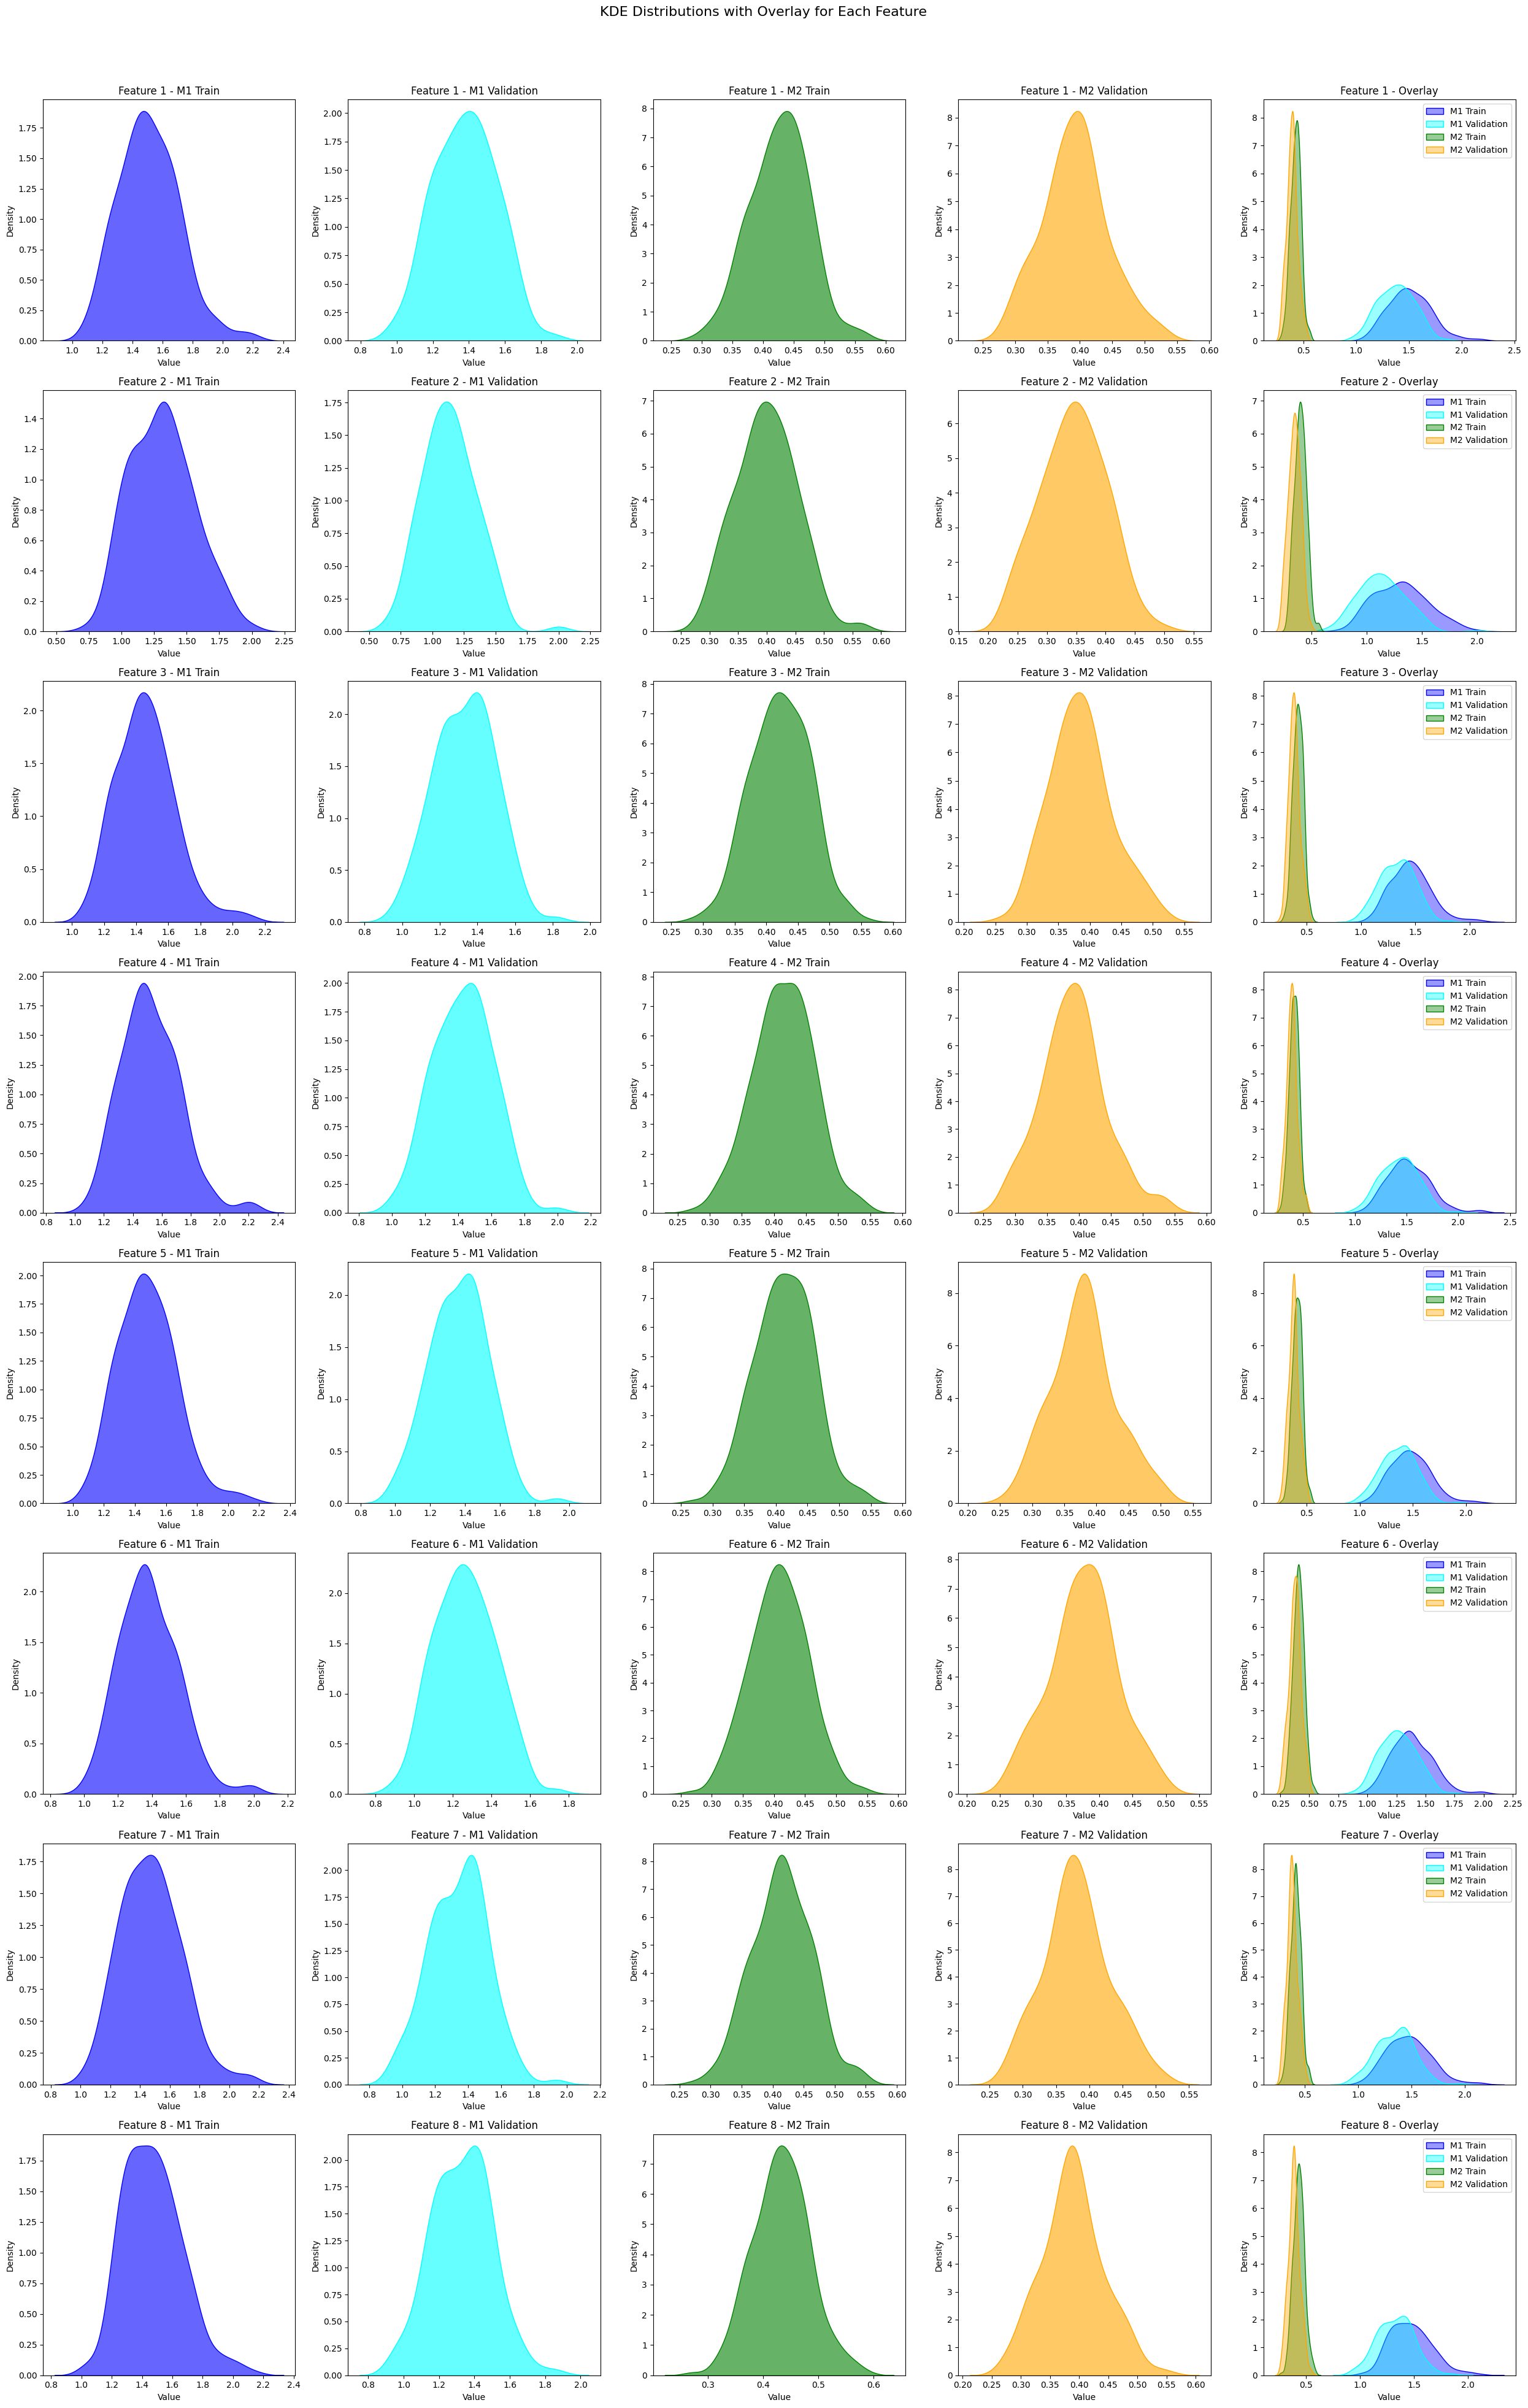

In [ ]:
#title1 = "PET Input Data (Healthy Control)"
#title2 = "PET Reconstruction Data (Healthy Control)"
#title3 = "MRI Input Data (Healthy Control)"
#title4 = "MRI Reconstruction Data (Healthy Control)"
# plot_kde_distributions(X1_valmod_hc_tensor, recon_hc_m1, X2_valmod_hc_tensor, recon_hc_m2, title1 = "PET Input Data (Healthy Control)", title2 = "PET Reconstruction Data (Healthy Control)", title3 = "MRI Input Data (Healthy Control)", title4 = "MRI Reconstruction Data (Healthy Control)", selected_features)


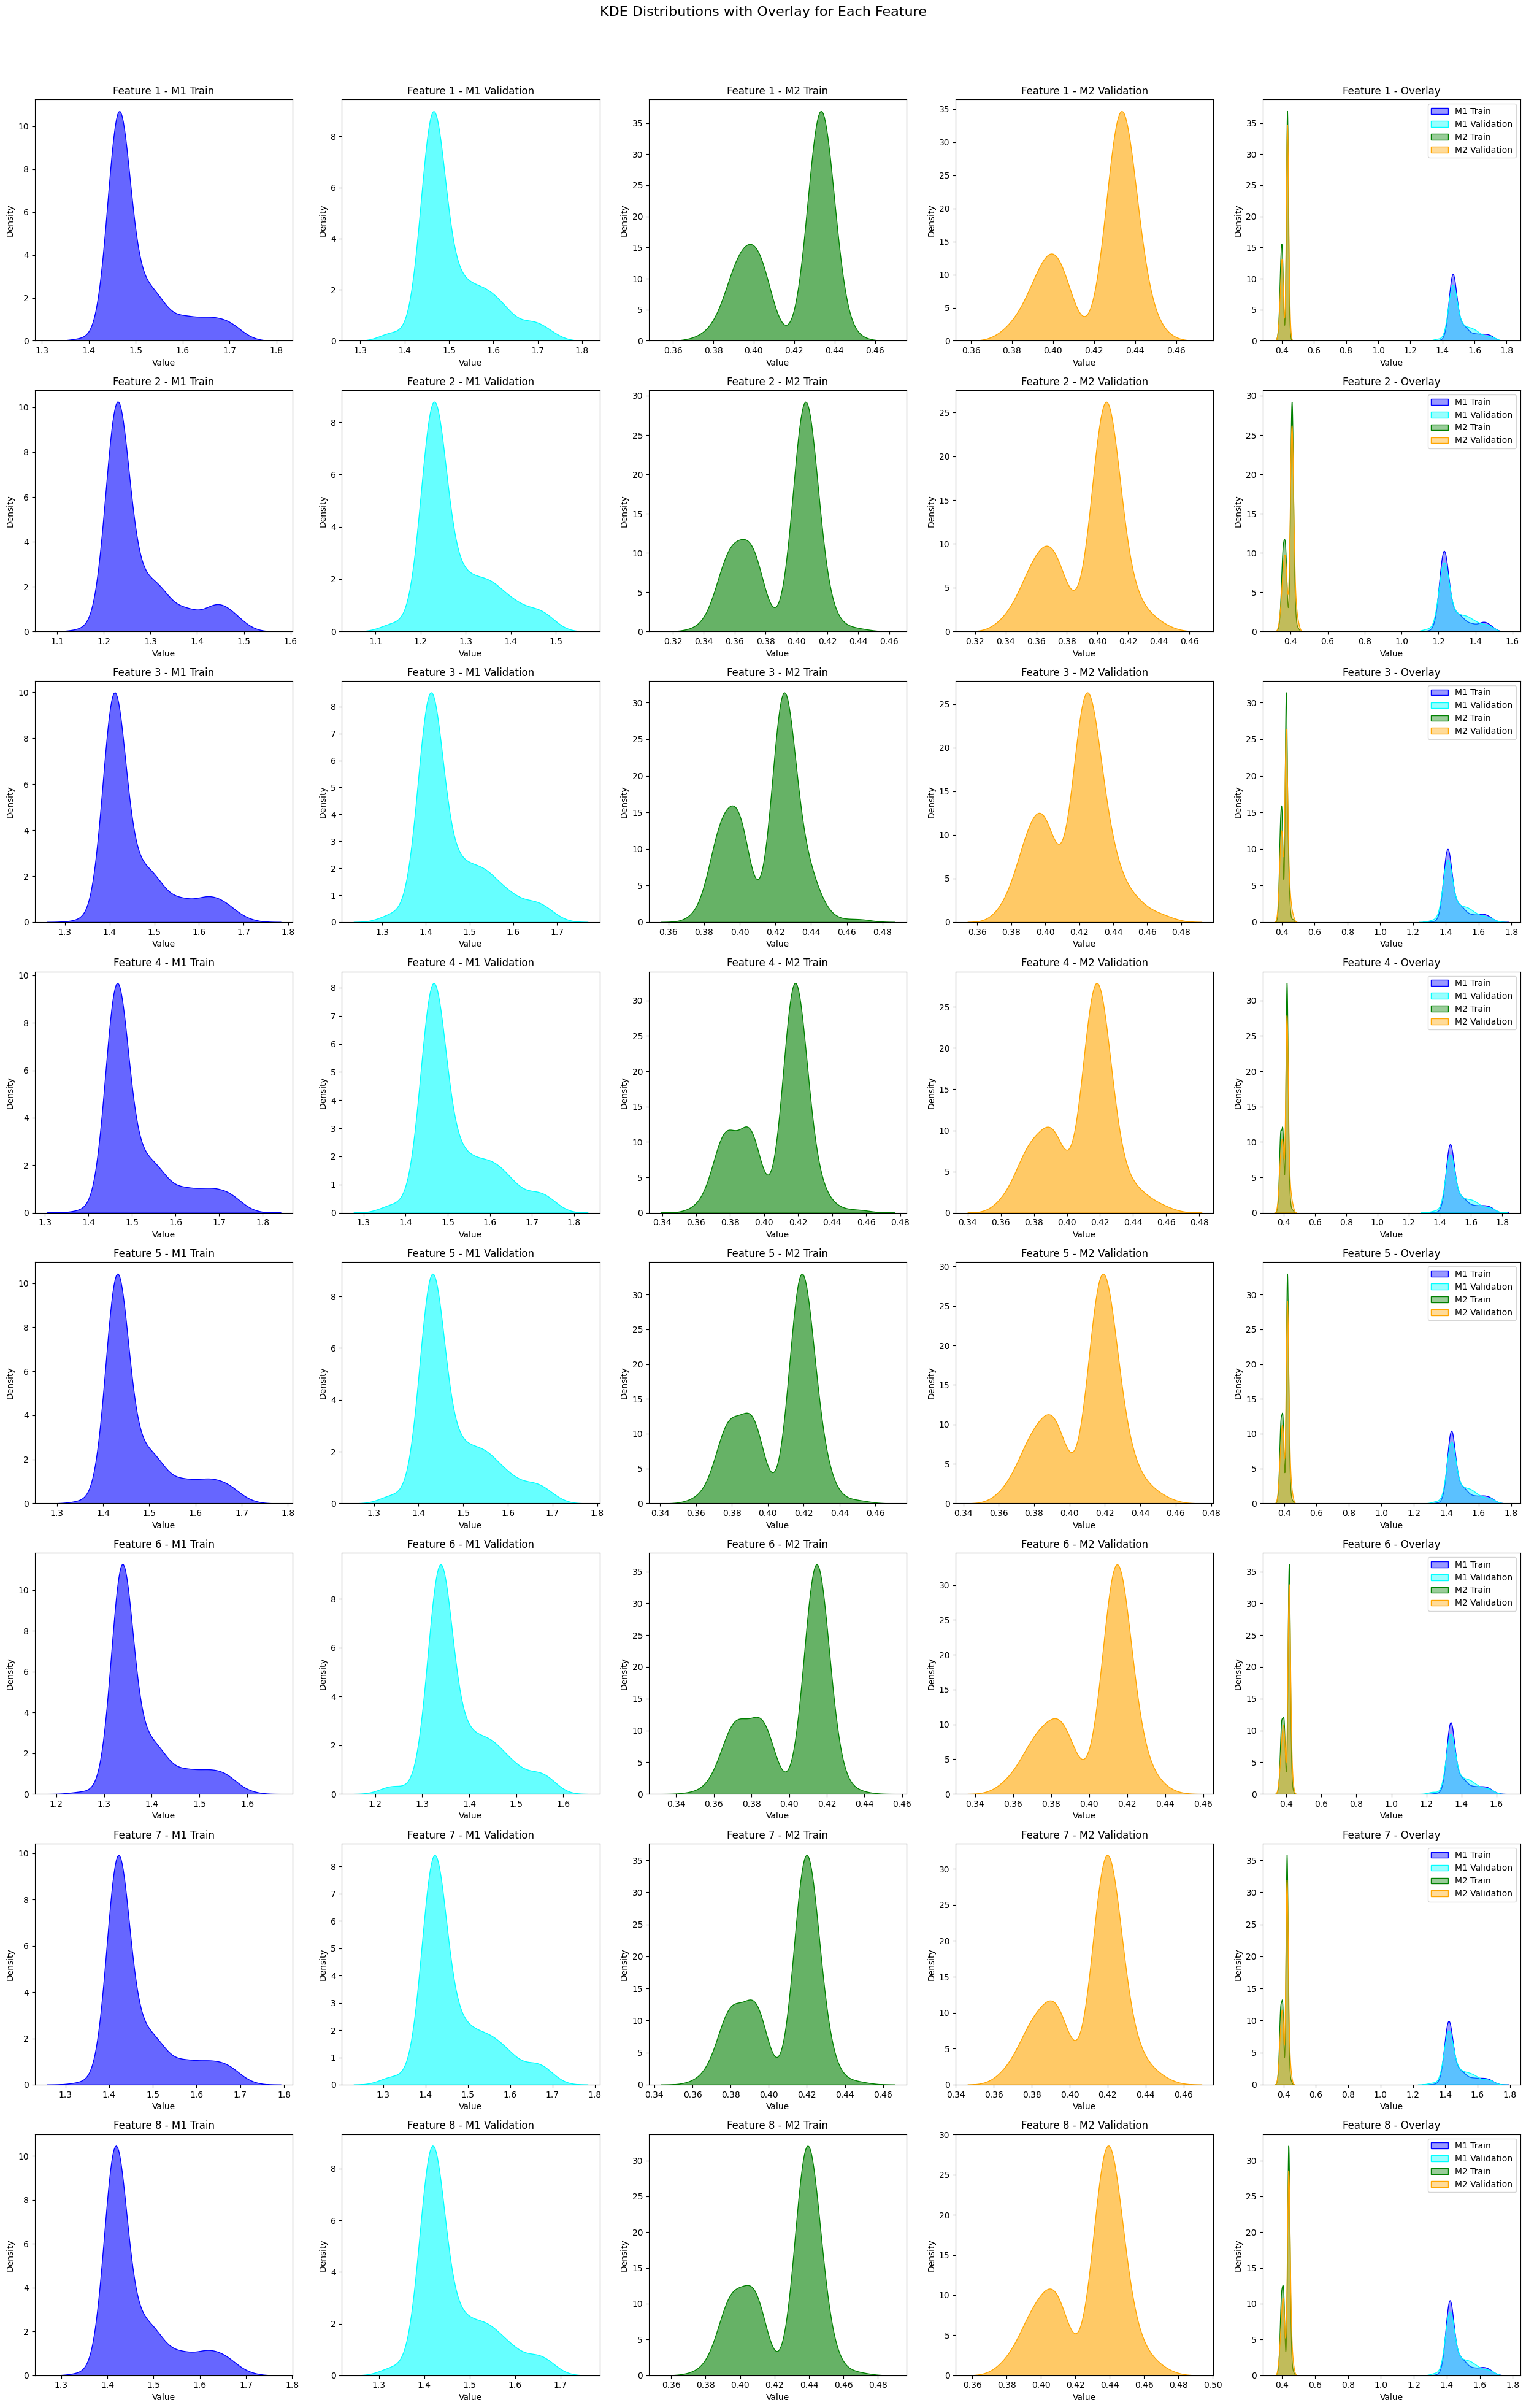

In [ ]:
#title1 = "PET Input Data (Alzheimer Disease)"
#title2 = "PET Reconstruction Data (Alzheimer Disease)"
#title3 = "MRI Input Data (Alzheimer Disease)"
#title4 = "MRI Reconstruction Data (Alzheimer Disease)"
# plot_kde_distributions(X1_valmod_ad_tensor, recon_ad_m1, X2_valmod_ad_tensor, recon_ad_m2, title1 = "PET Input Data (Alzheimer Disease)", title2 = "PET Reconstruction Data (Alzheimer Disease)", title3 = "MRI Input Data (Alzheimer Disease)", title4 = "MRI Reconstruction Data (Alzheimer Disease)", selected_features)


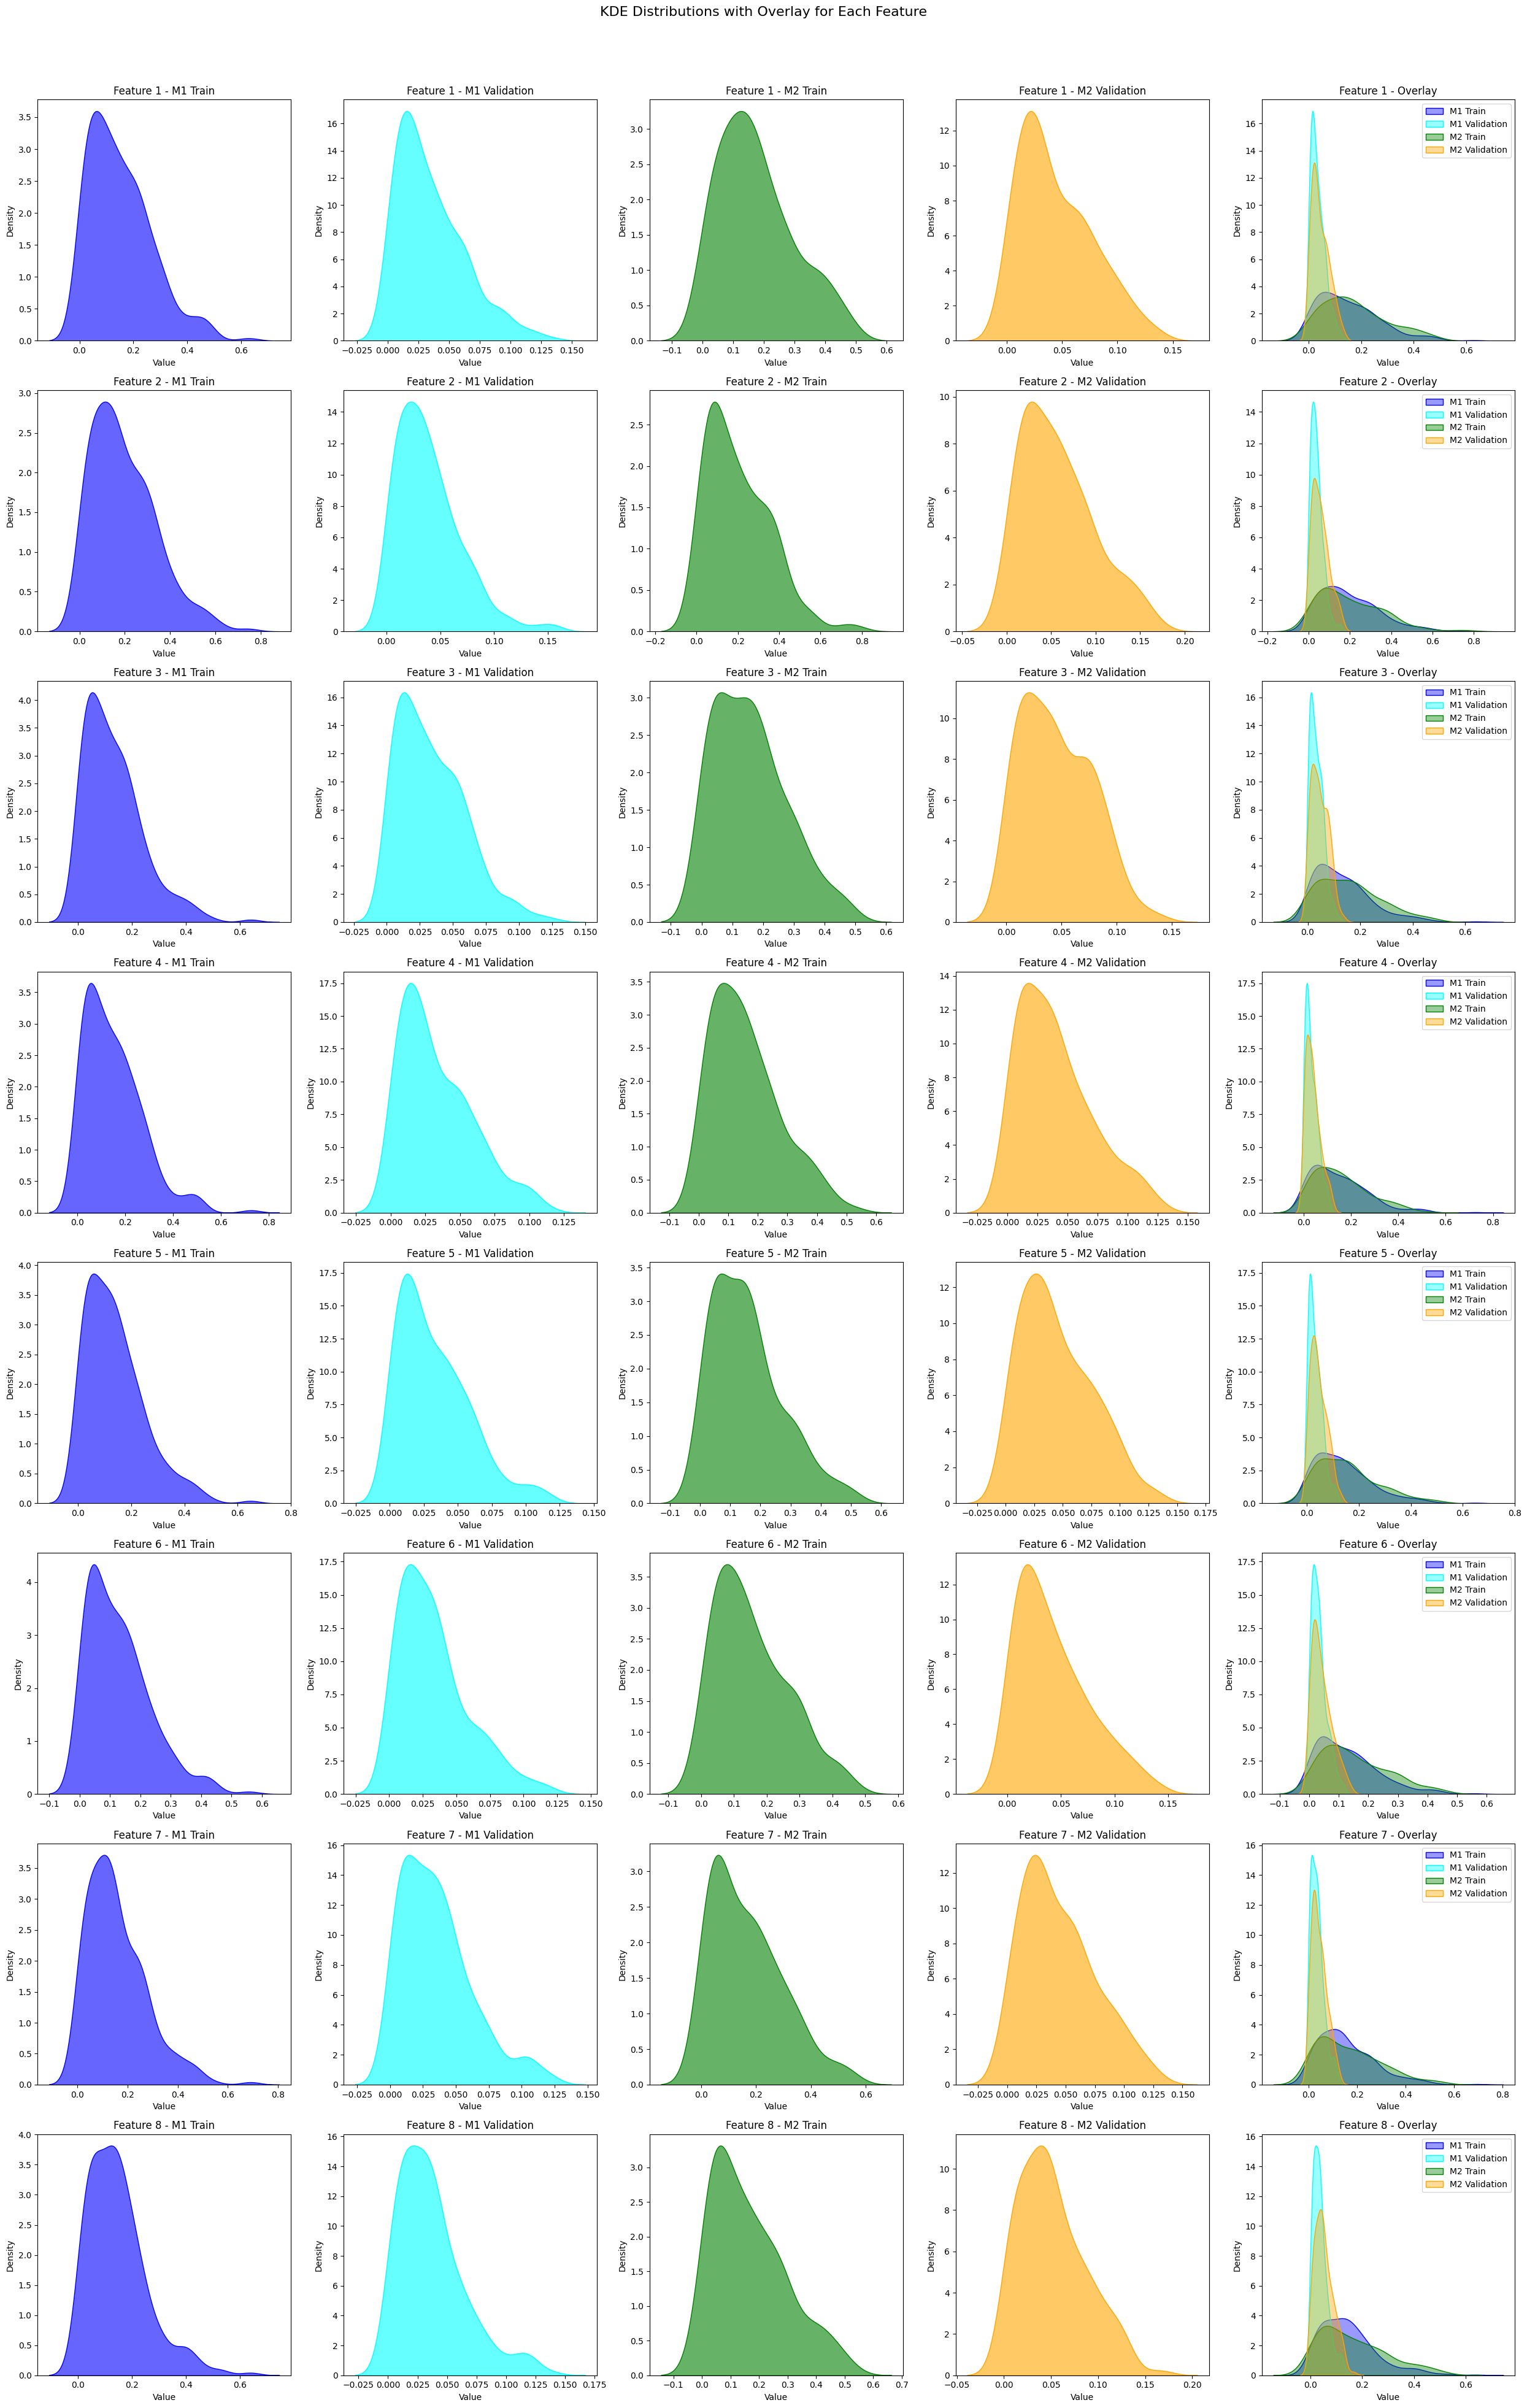

In [ ]:
#title1 = "PET differenes between Input and Recon (Healthy Control)"
#title2 = "MRI Differences between Input and Recon (Healthy Control)"
#title3 = "PET Differences between Input and Recon (Alzheimer Disease)"
#title4 = "MRI Differences between Input and Recon (Alzheimer Disease)"
# plot_kde_distributions(M1_diff_hc, M2_diff_hc, M1_diff_ad, M2_diff_ad, title1 = "PET differenes between Input and Recon (Healthy Control)", title2 = "MRI Differences between Input and Recon (Healthy Control)", title3 = "PET Differences between Input and Recon (Alzheimer Disease)", title4 = "MRI Differences between Input and Recon (Alzheimer Disease)", selected_features)


In [ ]:
title1 = "PET Input data (Healthy Control)"
title2 = "PET Reconstruction data (Healthy Control)"
plot_compare_histograms(X1_valmod_hc_tensor, recon_hc_m1, title1, title2, selected_features)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
title1 = "MRI Input data (Healthy Control)"
title2 = "MRI Reconstruction data (Healthy Control)"
plot_compare_histograms(X2_valmod_hc_tensor, recon_hc_m2, title1, title2, selected_features)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
title1 = "PET Input data (Alzheimer Disease)"
title2 = "PET Reconstruction data (Alzheimer disease)"
plot_compare_histograms(X1_valmod_ad_tensor, recon_ad_m1, title1, title2, selected_features)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
title1 = "MRI Input data (Alzheimer Disease)"
title2 = "MRI Reconstruction data (Alzheimer)"
plot_compare_histograms(X2_valmod_ad_tensor, recon_ad_m2, title1, title2, selected_features)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
def plot_dotplot_with_crossbar(data, title):
    """
    Create a dot plot with crossbars showing mean and standard deviation for each feature.

    Args:
        data: 2D numpy array with shape (samples, features), where features are plotted on the x-axis.
        title: Title for the plot.
    """
    # Calculate mean and standard deviation for each feature (column)
    feature_means = np.mean(data, axis=0)
    feature_stds = np.std(data, axis=0)
    num_features = data.shape[1]

    # Create the plot
    plt.figure(figsize=(16, 6))
    x_positions = np.arange(num_features)  # Feature indices

    # Scatter plot for individual data points
    for i in range(data.shape[0]):
        plt.scatter(x_positions, data[i], color='gray', alpha=0.5, s=10, label='_nolegend_')

    # Add crossbars (mean and std)
    plt.errorbar(
        x_positions, feature_means, yerr=feature_stds, fmt='o', color='blue', ecolor='red',
        elinewidth=1, capsize=3, label='Mean ± STD'
    )

    # Customize the plot
    plt.title(title, fontsize=16)
    plt.xlabel("Feature Index", fontsize=14)
    plt.ylabel("Values", fontsize=14)
    plt.xticks(ticks=x_positions, labels=np.arange(1, num_features + 1), rotation=90)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend(fontsize=12)
    plt.tight_layout()

    # Show the plot
    plt.show()


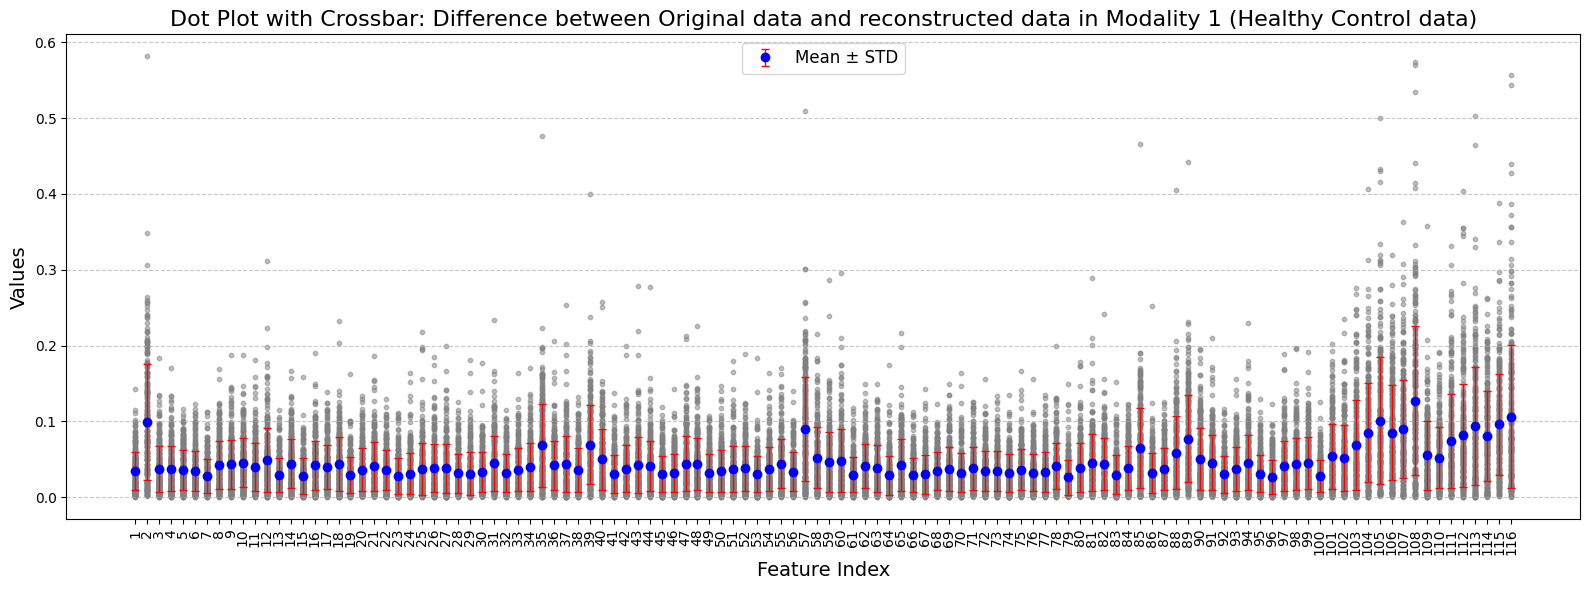

In [ ]:
plot_dotplot_with_crossbar(M1_diff_hc.cpu().numpy(), "Dot Plot with Crossbar: Difference between Original data and reconstructed data in Modality 1 (Healthy Control data)")


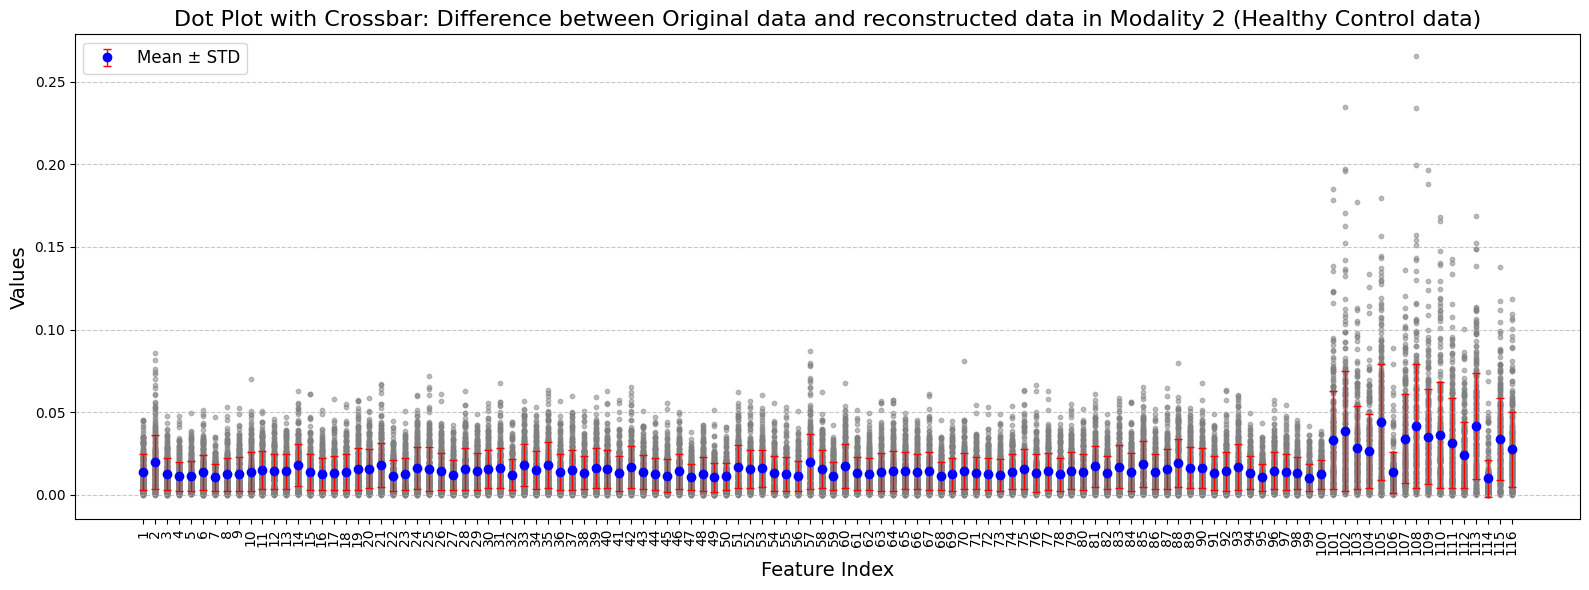

In [ ]:
plot_dotplot_with_crossbar(M2_diff_hc.cpu().numpy(), "Dot Plot with Crossbar: Difference between Original data and reconstructed data in Modality 2 (Healthy Control data)")


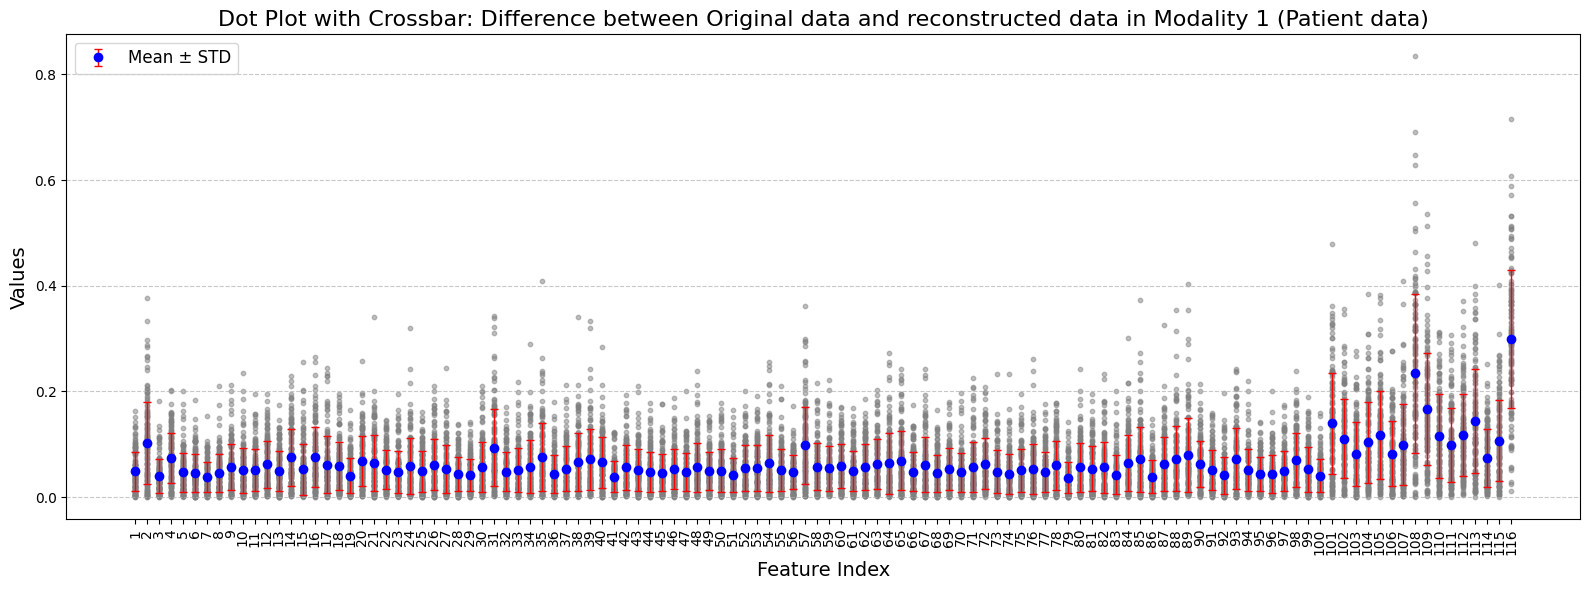

In [ ]:
plot_dotplot_with_crossbar(M1_diff_ad.cpu().numpy(), "Dot Plot with Crossbar: Difference between Original data and reconstructed data in Modality 1 (Patient data)")


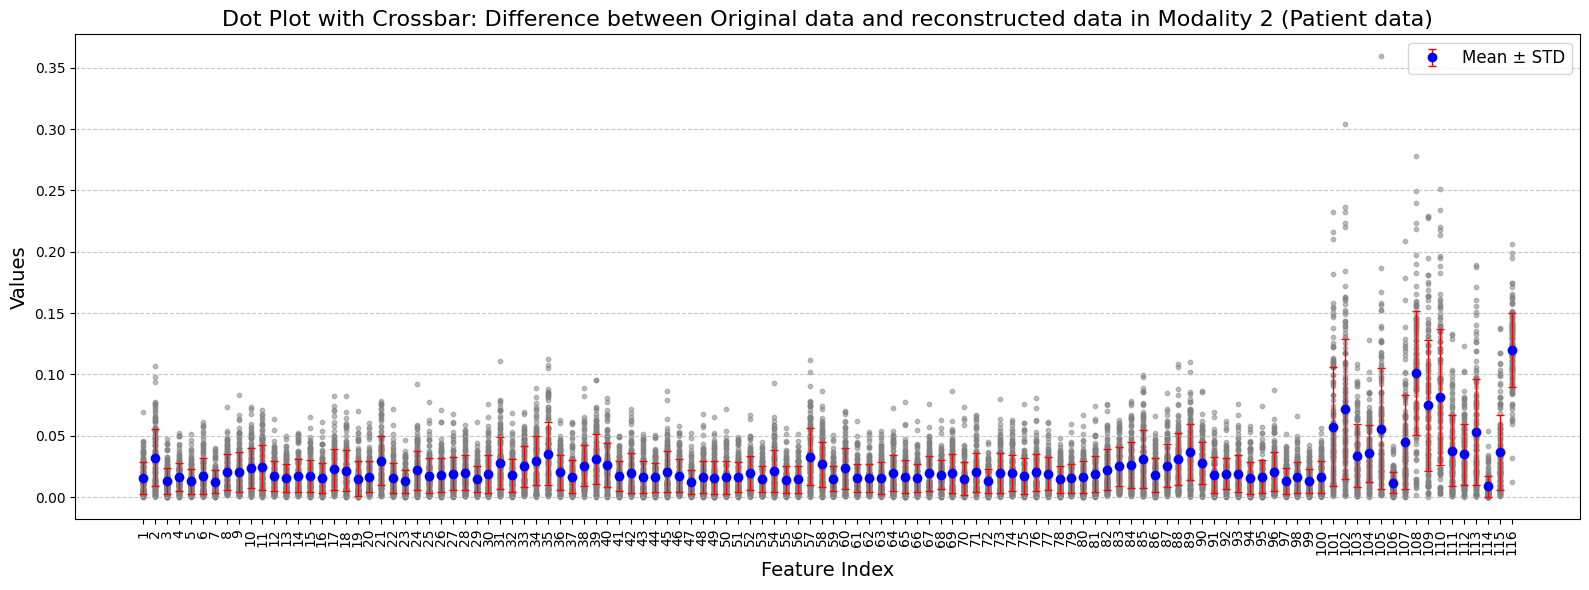

In [ ]:
plot_dotplot_with_crossbar(M2_diff_ad.cpu().numpy(), "Dot Plot with Crossbar: Difference between Original data and reconstructed data in Modality 2 (Patient data)")


In [ ]:
M1_diff_hc = M1_diff_hc[:, :roi_dim]
M2_diff_hc = M2_diff_hc[:, :roi_dim]

M1_diff_ad = M1_diff_ad[:, :roi_dim]
M2_diff_ad = M2_diff_ad[:, :roi_dim]


In [ ]:
M1_diff_hc = M1_diff_hc.cpu().numpy()
M2_diff_hc = M2_diff_hc.cpu().numpy()

M1_diff_ad = M1_diff_ad.cpu().numpy()
M2_diff_ad = M2_diff_ad.cpu().numpy()

In [ ]:
# Function to calculate deviations
def calculate_deviations(M1_diff_hc, M1_dij_ad, M2_diff_hc, M2_dij_ad):

    """Calculate the deviations for disease patients compared to healthy controls."""

    M1_dij_hc_mean = np.mean(M1_diff_hc, axis=0)
    M1_dij_hc_std = np.std(M1_diff_hc, axis=0)

    print(f"Modality1 diff (difference between ground truth and reconstruction) Healthy Conrol data mean shape is : {M1_dij_hc_mean.shape}")
    print(f"Modality1 diff (difference between ground truth and reconstruction) Healthy Conrol data mean (per column): {M1_dij_hc_mean}")
    print(f"Modality1 diff (difference between ground truth and reconstruction) Healthy Conrol data std shape: {M1_dij_hc_std.shape}")
    print(f"Modality1 diff (difference between ground truth and reconstruction) Healthy Conrol data std (per column): {M1_dij_hc_std}")

    # Calculate Deviation for Modality 1
    M1_dev = (M1_dij_ad - M1_dij_hc_mean) / M1_dij_hc_std

    M2_dij_hc_mean = np.mean(M2_diff_hc, axis=0)
    M2_dij_hc_std = np.std(M2_diff_hc, axis=0)

    print(f"Modality2 diff (difference between ground truth and reconstruction) Healthy Conrol data mean shape is : {M2_dij_hc_mean.shape}")
    print(f"Modality2 diff (difference between ground truth and reconstruction) Healthy Conrol data mean (per column): {M2_dij_hc_mean}")
    print(f"Modality2 diff (difference between ground truth and reconstruction) Healthy Conrol data std shape: {M2_dij_hc_std.shape}")
    print(f"Modality2 diff (difference between ground truth and reconstruction) Healthy Conrol data std (per column): {M2_dij_hc_std}")

    # Calculate Deviation for Modality 2
    M2_dev = (M2_dij_ad - M2_dij_hc_mean) / M2_dij_hc_std

    return M1_dev, M2_dev

In [ ]:
# Calculate deviations
M1_dev, M2_dev = calculate_deviations(M1_diff_hc, M1_diff_ad, M2_diff_hc, M2_diff_ad)


Modality1 diff (difference between ground truth and reconstruction) Healthy Conrol data mean shape is : (116,)
Modality1 diff (difference between ground truth and reconstruction) Healthy Conrol data mean (per column): [0.03400814 0.09933203 0.03701909 0.03761015 0.03604314 0.03434939
 0.02730547 0.04242921 0.04344104 0.0451238  0.03998248 0.04928228
 0.02937899 0.04402803 0.0278425  0.04180086 0.03987243 0.04384702
 0.029594   0.0358991  0.04037952 0.03533667 0.02814617 0.03060503
 0.03718809 0.03834579 0.03775574 0.03147048 0.0309104  0.03346822
 0.04454114 0.03190057 0.03635475 0.03992315 0.06816755 0.04176694
 0.04336208 0.03542602 0.06884915 0.05018232 0.03077603 0.03766046
 0.04260053 0.04122576 0.03041859 0.03188783 0.04394604 0.04395515
 0.03183711 0.03443299 0.03719946 0.03791121 0.03028981 0.03662751
 0.04417712 0.03364819 0.08960453 0.05216335 0.04672777 0.04818972
 0.02932804 0.04094448 0.03783998 0.0288909  0.04222934 0.02915389
 0.02995439 0.03410501 0.03676555 0.03205187 

In [ ]:
print(M1_dev)

[[ 0.69311845 -0.01675948 -0.1967804  ... -1.0997444  -0.03699666
   2.1669335 ]
 [ 2.0277996  -0.38256297 -0.5679617  ... -0.0924151   1.0451059
   1.8748318 ]
 [-0.62763286 -0.5754675  -0.9887708  ... -1.1980209  -0.81421983
   1.6179733 ]
 ...
 [-0.7238952   0.3652283   0.20968613 ... -1.0653338  -0.68066645
   0.558766  ]
 [ 0.6206659   0.40789458  0.523985   ...  1.1017143   1.6696137
   2.2941592 ]
 [ 0.45259047 -0.23921806 -0.05721408 ...  0.32310373 -0.8878404
   2.2271123 ]]


In [ ]:
print(M2_dev)

[[ 0.84507287  2.0633292  -0.05173905 ... -0.17426005 -0.67366046
   5.4918222 ]
 [ 1.2697024   3.544502   -0.283291   ... -0.48573774 -0.03141546
   4.820669  ]
 [-0.9687807  -0.8279078   0.26525888 ...  0.0729666   0.16184859
   5.2248325 ]
 ...
 [-0.33704105 -1.0905513  -0.3759812  ... -0.807546   -0.5813575
   3.3453052 ]
 [ 2.9078882  -0.7095504   1.442969   ... -0.42274877 -0.46177977
   3.4004903 ]
 [ 2.8550403   2.8187633  -0.33393863 ...  0.08146806  0.31691593
   5.455934  ]]


In [ ]:
# Compute and print mean values
#M1_dev_mean = np.mean(M1_dev)
#M2_dev_mean = np.mean(M2_dev)

#print(f"Mean of M1_dev: {M1_dev_mean}")
#print(f"Mean of M2_dev: {M2_dev_mean}")

Mean of M1_dev: 0.5845998525619507
Mean of M2_dev: 0.5154183506965637


In [ ]:
print(M1_dev.shape)
print(M2_dev.shape)

(139, 116)
(139, 116)


In [ ]:
def plot_dev_histograms(M1_dev, M2_dev, feature_indices):
    """
    Plots individual histograms for each dataset and an overlayed histogram for each selected feature.

    Parameters:
    - M1_dev, M2_dev: Numpy arrays of shape (N, 116).
    - feature_indices: List of feature indices to plot (max 8 features).
    """
    num_features = len(feature_indices)


    titles = ["PET Deviation", "MRI Deviation"]
    data_sets = [M1_dev, M2_dev]
    colors = ["blue", "cyan"]

    fig, axes = plt.subplots(num_features, 3, figsize=(25, num_features * 3))  # 3 columns per feature
    fig.suptitle("Histogram Comparisons with Overlay for Each Feature", fontsize=16)

    for row_idx, feature in enumerate(feature_indices):
        # Plot individual histograms
        for col_idx in range(2):
            ax = axes[row_idx, col_idx]
            ax.hist(data_sets[col_idx][:, feature], bins=20, alpha=0.7, color=colors[col_idx])
            ax.set_title(f"Feature {feature+1} - {titles[col_idx]}")
            ax.set_xlabel("Value")
            ax.set_ylabel("Frequency")

        # Plot overlayed histogram in the last column
        ax = axes[row_idx, 2]
        for data, color, label in zip(data_sets, colors, titles):
            ax.hist(data[:, feature], bins=20, alpha=0.5, color=color, label=label)
        ax.set_title(f"Feature {feature+1} - Overlay")
        ax.set_xlabel("Value")
        ax.set_ylabel("Frequency")
        ax.legend()

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [ ]:
plot_dev_histograms(M1_dev, M2_dev, selected_features)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
def identify_significant_deviations(M1_dev, M2_dev, alpha=0.05):
    """
    Identify brain regions with significant deviations based on Z-scores for modalities 1 and 2.

    Args:
        M1_dev: 2D array of shape (patients, regions) for Z-scores in modality 1.
        M2_dev: 2D array of shape (patients, regions) for Z-scores in modality 2.
        alpha: Significance threshold for identifying significant deviations (default=0.05).

    Returns:
        significant_regions: A dictionary with patient indices as keys, and for each patient, a list of regions with significant deviations in M1 and M2.
    """
    # Calculate p-values from Z-scores for both modalities
    M1_p_values = 2 * norm.sf(np.abs(M1_dev))  # Two-tailed test
    M2_p_values = 2 * norm.sf(np.abs(M2_dev))  # Two-tailed test

    significant_regions = {}

    for patient_idx in range(M1_dev.shape[0]):
        # Find regions with significant deviations in M1 and M2
        significant_M1 = np.where(M1_p_values[patient_idx] < alpha)[0]
        significant_M2 = np.where(M2_p_values[patient_idx] < alpha)[0]

        # Add to the result if there are significant deviations
        if len(significant_M1) > 0 or len(significant_M2) > 0:
            significant_regions[patient_idx] = {
                "M1_significant_regions": significant_M1.tolist(),
                "M2_significant_regions": significant_M2.tolist(),
            }

    # Print the results
    for patient, regions in significant_regions.items():
        print(f"Patient {patient + 1}:")
        if len(regions["M1_significant_regions"]) > 0:
            print(f"  Significant regions in Modality 1: {regions['M1_significant_regions']}")
        if len(regions["M2_significant_regions"]) > 0:
            print(f"  Significant regions in Modality 2: {regions['M2_significant_regions']}")

    return significant_regions


In [ ]:
# Shape: (140 patients, 116 regions)
significant_regions = identify_significant_deviations(M1_dev, M2_dev, alpha=0.05)

Patient 1:
  Significant regions in Modality 1: [107, 115]
  Significant regions in Modality 2: [1, 8, 10, 44, 56, 88, 90, 107, 115]
Patient 2:
  Significant regions in Modality 1: [0, 16, 66, 70, 72, 95, 100, 101, 107]
  Significant regions in Modality 2: [1, 7, 8, 9, 10, 16, 17, 20, 30, 31, 32, 33, 34, 38, 53, 56, 57, 67, 68, 70, 72, 81, 83, 84, 87, 88, 95, 107, 111, 115]
Patient 3:
  Significant regions in Modality 2: [39, 89, 107, 112, 115]
Patient 4:
  Significant regions in Modality 1: [16, 20, 29, 32, 33, 39, 41, 60, 73, 74, 75, 76, 80, 83, 86, 89, 100, 101, 106, 108, 114]
  Significant regions in Modality 2: [1, 13, 17, 26, 56, 68, 94, 95, 100, 115]
Patient 5:
  Significant regions in Modality 1: [5, 13, 20, 62, 72, 109]
  Significant regions in Modality 2: [10, 26, 31, 33, 34, 37, 44, 57, 79, 84, 88, 103, 111, 115]
Patient 6:
  Significant regions in Modality 1: [18, 74, 100, 101, 107, 108, 109, 115]
  Significant regions in Modality 2: [0, 1, 3, 5, 6, 7, 8, 9, 10, 12, 14, 16,

In [ ]:
def plot_significant_z_scores(M1_dev, M2_dev):
    """
    Plot a dot plot for Z-scores of all patients (y-axis) across features (x-axis),
    with dots colored red for significant p-values (<0.05) and blue otherwise.

    Args:
        M1_dev: 2D array (140 patients, 116 regions) of Z-scores in modality 1.
        M2_dev: 2D array (140 patients, 116 regions) of Z-scores in modality 2.
    """
    num_patients, num_features = M1_dev.shape

    # Calculate p-values for Z-scores
    p_values_m1 = 2 * (1 - norm.cdf(np.abs(M1_dev)))  # Two-tailed test
    p_values_m2 = 2 * (1 - norm.cdf(np.abs(M2_dev)))  # Two-tailed test

    # Create a dot plot for Modality 1
    plt.figure(figsize=(20, 8))
    for patient_idx in range(num_patients):
        for feature_idx in range(num_features):
            color = 'red' if p_values_m1[patient_idx, feature_idx] < 0.05 else 'black'
            plt.scatter(feature_idx, patient_idx, color=color, s=10, alpha=0.7)

    plt.title("Dot Plot of Z-Scores for Modality 1", fontsize=16)
    plt.xlabel("Features (Brain Regions)", fontsize=14)
    plt.ylabel("Patients", fontsize=14)
    plt.grid(alpha=0.3)
    plt.show()

    # Create a dot plot for Modality 2
    plt.figure(figsize=(20, 8))
    for patient_idx in range(num_patients):
        for feature_idx in range(num_features):
            color = 'red' if p_values_m2[patient_idx, feature_idx] < 0.05 else 'black'
            plt.scatter(feature_idx, patient_idx, color=color, s=10, alpha=0.7)

    plt.title("Dot Plot of Z-Scores for Modality 2", fontsize=16)
    plt.xlabel("Features (Brain Regions)", fontsize=14)
    plt.ylabel("Patients", fontsize=14)
    plt.grid(alpha=0.3)
    plt.show()


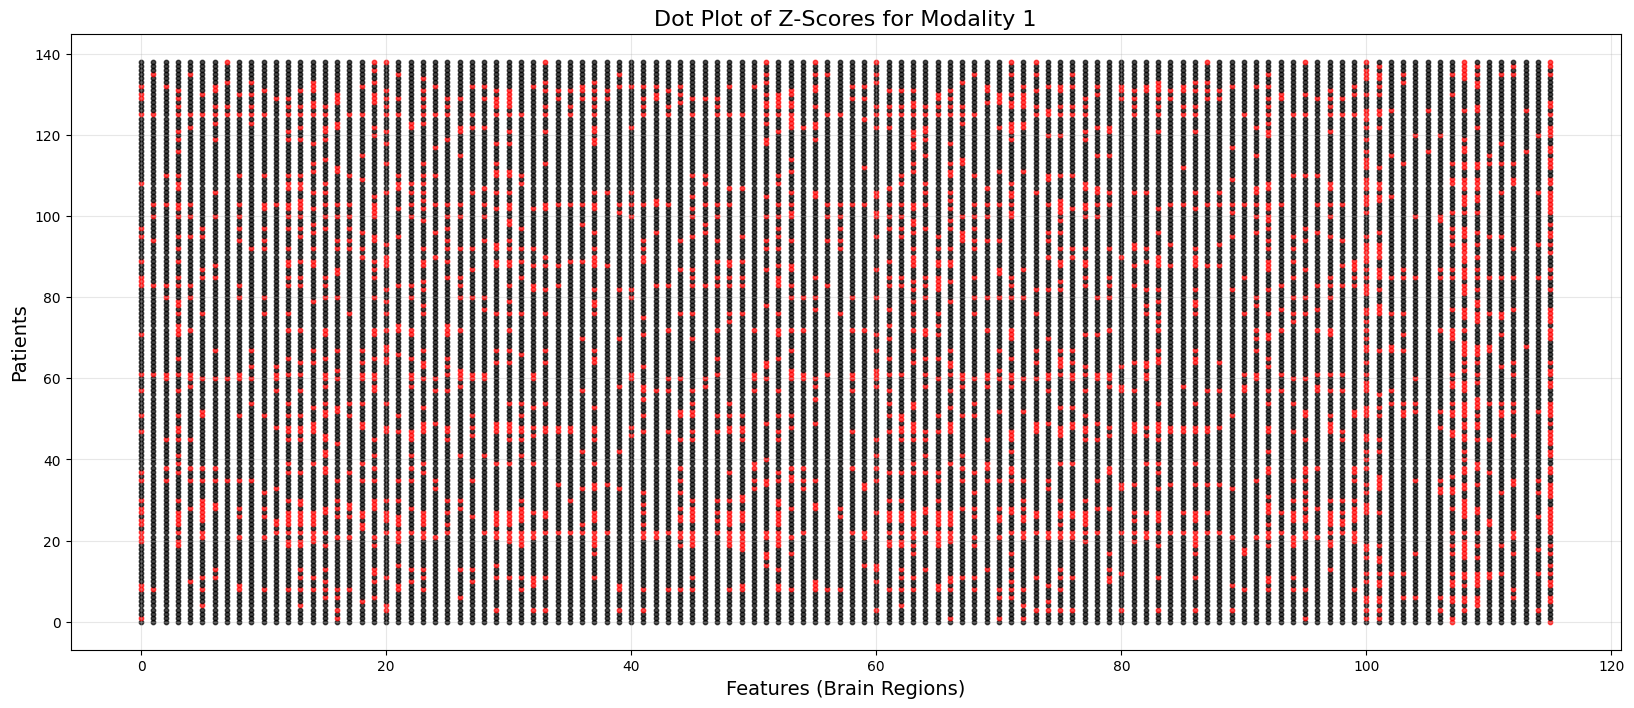

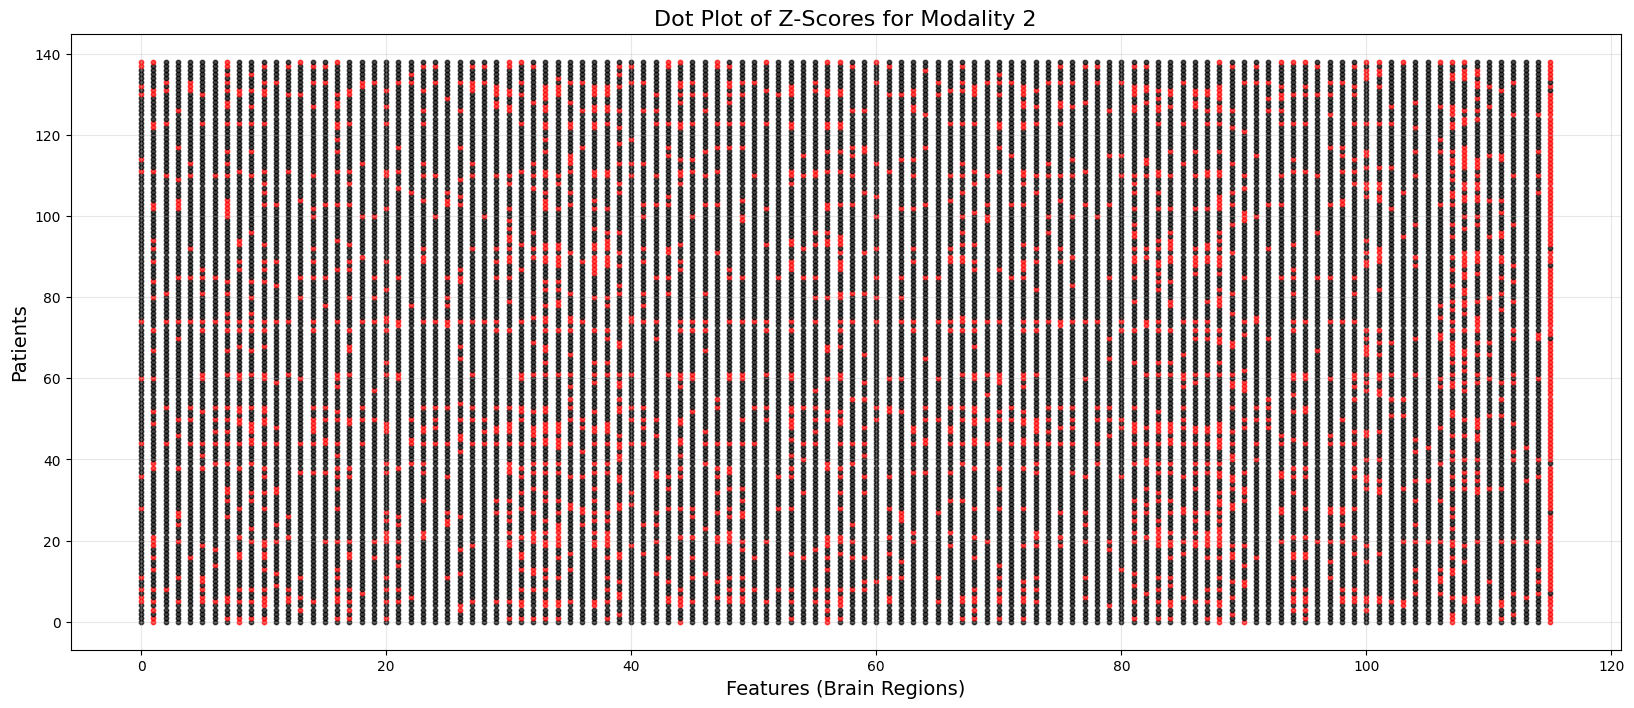

In [ ]:
plot_significant_z_scores(M1_dev, M2_dev)

In [ ]:
def plot_z_scores(M1_dev, M2_dev):
    """
    Plot Z-scores for all regions for each patient in two modalities (M1 and M2).

    Args:
        M1_dev: 2D array (139 patients, 116 regions) of Z-scores in modality 1.
        M2_dev: 2D array (139 patients, 116 regions) of Z-scores in modality 2.
    """
    num_patients, num_regions = M1_dev.shape

    for patient_idx in range(num_patients):
        plt.figure(figsize=(12, 6))
        plt.title(f"Z-Scores for Patient {patient_idx + 1}", fontsize=16)
        plt.xlabel("Region Index (Brain Regions)", fontsize=14)
        plt.ylabel("Z-Score", fontsize=14)

        # Plot Z-scores for Modality 1
        plt.plot(range(num_regions), M1_dev[patient_idx], label="Modality 1", marker='o', linestyle='-', alpha=0.7)

        # Plot Z-scores for Modality 2
        plt.plot(range(num_regions), M2_dev[patient_idx], label="Modality 2", marker='s', linestyle='--', alpha=0.7)

        # Add legend
        plt.legend(loc="upper right", fontsize=12)

        # Add grid for readability
        plt.grid(alpha=0.4)

        # Save or show the figure
        plt.tight_layout()
        plt.show()

In [ ]:
plot_z_scores(M1_dev, M2_dev)

Output hidden; open in https://colab.research.google.com to view.